# Pemodelan Bi-LSTM: Pemetaan Fase Tumbuh Padi


## Library

In [1]:
!pip install tensorflow optuna -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 26.9 MB/s eta 0:00:00


In [2]:
import os, gc, time, random, pickle, joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, cohen_kappa_score
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (Input, Bidirectional, LSTM, Dense,
                                     TimeDistributed, Lambda, Dropout)
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import backend as K

import optuna
from optuna.samplers import GPSampler
import optuna.visualization as vis

## Persiapan Data

> Data dimuat langsung dari file `.npy` hasil ekspor **Skripsi_Step2_Preparation_Data_UPDATED**.
> Seluruh proses splitting, Winsorizing, dan Min-Max Normalisasi sudah dilakukan di file Preparation.
> **Tidak ada splitting atau scaling tambahan di file ini.**

In [3]:
# GPU Check
if tf.test.gpu_device_name():
    print('GPU AKTIF: ' + tf.test.gpu_device_name())
else:
    print("MENGGUNAKAN CPU")

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

GPU AKTIF: /device:GPU:0
Mounted at /content/drive


In [4]:
# ── KONFIGURASI GLOBAL ──────────────────────────────────────────────────────
CONFIG = {
    # ── PATH DATA ────────────────────────────────────────────────────────────
    "npy_dir": '/content/drive/MyDrive/Skripsi/04. Data Ready Bi-LSTM/Split_NPY_v2',
    "root_dir": '/content/drive/MyDrive/Skripsi/05. Modeliling with Winsorizing',

    # ── FITUR & LABEL ─────────────────────────────────────────────────────────
    "features": [
        'VV_db', 'VH_db', 'RPI', 'NDPI', 'API',   # Radar
        'B2', 'B3', 'B4', 'B8', 'B11',            # Optik
        'EVI', 'LSWI'                             # Indeks
    ],
    "label_col":   'Label_Final',
    "num_classes": 6,
    "random_seed": 42,
}

NAMA_KELAS = ['Vegetatif Awal', 'Vegetatif Akhir', 'Generatif',
              'Panen', 'Persiapan Lahan', 'Bera']

os.makedirs(CONFIG["root_dir"], exist_ok=True)


In [5]:
# ── FUNGSI UTILITAS ─────────────────────────────────────────────────────────
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'

def subset_output(x):
    """Ambil 6 prediksi dari 12 timestep (indeks ganjil = periode P2)."""
    return x[:, 1::2, :]

def plot_learning_curve(history_dict, title, save_path=None):
    h = history_dict
    best_epoch = np.argmin(h['val_loss']) + 1
    epochs = range(1, len(h['loss']) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(title, fontsize=13, fontweight='bold')

    for ax, metric, val_metric, ylabel in zip(
        axes,
        ['accuracy', 'loss'], ['val_accuracy', 'val_loss'],
        ['Accuracy', 'Loss']
    ):
        ax.plot(epochs, h[metric],     'b-',  label='Train')
        ax.plot(epochs, h[val_metric], 'r--', label='Val')
        ax.axvline(best_epoch, color='green', linestyle=':', label=f'Best ({best_epoch})')
        ax.scatter(best_epoch, h[val_metric][best_epoch-1], color='green', s=60, zorder=5)
        ax.set_xlabel('Epochs'); ax.set_ylabel(ylabel)
        ax.set_title(f'{ylabel} Curve'); ax.legend(); ax.grid(True, alpha=0.3)
        ax.grid(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    cm      = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    for ax, data, fmt, cmap, subtitle in zip(
        axes,
        [cm, cm_norm], ['d', '.2f'],
        ['Blues', 'Greens'],
        ['Absolute', 'Normalized']
    ):
        sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap, ax=ax,
                    xticklabels=class_names, yticklabels=class_names)
        ax.set_title(f'{title} - {subtitle}')
        ax.set_xlabel('Prediksi'); ax.set_ylabel('Ground Truth')
        ax.grid(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

def evaluate_model(model, X_test, y_test, class_names, title, save_dir):
    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred = y_pred_prob.argmax(axis=2).flatten()
    y_true = y_test.argmax(axis=2).flatten()

    # Classification Report
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # Metrik
    acc = accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    print(f"Test Accuracy : {acc:.4%}")
    print(f"Cohen's Kappa : {kappa:.4f}")

    # Confusion Matrix
    cm_path = os.path.join(save_dir, f"CM_{title.replace(' ','_')}.png")
    plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=cm_path)
    return acc, kappa

In [6]:
# ── LOAD DATA 3D DARI HASIL FILE PREPARATION ────────────────────────────────
# Data sudah bersih, ternormalisasi, dan berbentuk array 3D.
# Tidak ada proses splitting atau scaling di sini.
# ─────────────────────────────────────────────────────────────────────────────
npy_dir = CONFIG["npy_dir"]

npy_files = {
    'X_train': os.path.join(npy_dir, 'X_train.npy'),
    'X_val'  : os.path.join(npy_dir, 'X_val.npy'),
    'X_test' : os.path.join(npy_dir, 'X_test.npy'),
    'y_train': os.path.join(npy_dir, 'y_train.npy'),
    'y_val'  : os.path.join(npy_dir, 'y_val.npy'),
    'y_test' : os.path.join(npy_dir, 'y_test.npy'),
}
scaler_path = os.path.join(npy_dir, 'scaler.joblib')

# Pastikan semua file tersedia
missing_files = [k for k, p in npy_files.items() if not os.path.exists(p)]
if missing_files:
    raise FileNotFoundError(
        f"File berikut tidak ditemukan di '{npy_dir}':\n"
        + "\n".join(missing_files)
        + "\n\nPastikan Skripsi_Step2_Preparation_Data_UPDATED sudah dijalankan terlebih dahulu!"
    )

print("Memuat data 3D dari file .npy hasil Preparation...")
X_train_sc = np.load(npy_files['X_train'])
X_val_sc   = np.load(npy_files['X_val'])
X_test_sc  = np.load(npy_files['X_test'])
y_train    = np.load(npy_files['y_train'])
y_val      = np.load(npy_files['y_val'])
y_test     = np.load(npy_files['y_test'])

# Load scaler (tersimpan jika dibutuhkan untuk inferensi di luar notebook)
if os.path.exists(scaler_path):
    loaded_scaler = joblib.load(scaler_path)
    print(f"Scaler berhasil dimuat: {scaler_path}")

total = len(X_train_sc) + len(X_val_sc) + len(X_test_sc)

print(f"\n[DISTRIBUSI SPLIT (Non-Leakage Spasial)]")
print(f"{'-'*55}")
print(f"{'Set':<12} | {'Sampel':<8} | {'Persen':<8} | Shape X")
print(f"{'-'*55}")
print(f"{'Training':<12} | {len(X_train_sc):<8} | {len(X_train_sc)/total:<8.1%} | {X_train_sc.shape}")
print(f"{'Validation':<12} | {len(X_val_sc):<8} | {len(X_val_sc)/total:<8.1%} | {X_val_sc.shape}")
print(f"{'Testing':<12} | {len(X_test_sc):<8} | {len(X_test_sc)/total:<8.1%} | {X_test_sc.shape}")
print(f"{'-'*55}")
print(f"Total         : {total} sampel")
print(f"\n[KONFIGURASI SIAP MODEL]")
print(f"Jumlah Kelas   : {CONFIG['num_classes']}")
print(f"Jumlah Fitur   : {X_train_sc.shape[2]} | Timestep: {X_train_sc.shape[1]}")
print(f"Input Shape    : {X_train_sc.shape[1:]}")
print(f"Output Shape   : {y_train.shape[1:]}")

Memuat data 3D dari file .npy hasil Preparation...
Scaler berhasil dimuat: /content/drive/MyDrive/Skripsi/04. Data Ready Bi-LSTM/Split_NPY_v2/scaler.joblib

[DISTRIBUSI SPLIT (Non-Leakage Spasial)]
-------------------------------------------------------
Set          | Sampel   | Persen   | Shape X
-------------------------------------------------------
Training     | 1856     | 80.1%    | (1856, 12, 12)
Validation   | 231      | 10.0%    | (231, 12, 12)
Testing      | 231      | 10.0%    | (231, 12, 12)
-------------------------------------------------------
Total         : 2318 sampel

[KONFIGURASI SIAP MODEL]
Jumlah Kelas   : 6
Jumlah Fitur   : 12 | Timestep: 12
Input Shape    : (12, 12)
Output Shape   : (6, 6)


---
# Tujuan 1a: Optimasi Arsitektur Bi-LSTM (Optuna GPSampler)

In [7]:
# ── KONFIGURASI TUJUAN 1a ────────────────────────────────────────────────────
T1A_NAMA       = "Model Peneliti"
T1A_N_TRIALS   = 50
T1A_EPOCHS     = 100
T1A_PATIENCE   = 10
T1A_STUDY_NAME = "optimasi_bilstm_gp"

T1A_BASE_DIR    = os.path.join(CONFIG["root_dir"], T1A_NAMA)
T1A_DIR_MODEL   = os.path.join(T1A_BASE_DIR, 'Model')
T1A_DIR_HISTORY = os.path.join(T1A_BASE_DIR, 'History')
T1A_PATH_EXCEL  = os.path.join(T1A_BASE_DIR, 'Rekap_Optuna.xlsx')
T1A_PATH_DB     = os.path.join(T1A_BASE_DIR, 'optuna_study.db')

for d in [T1A_BASE_DIR, T1A_DIR_MODEL, T1A_DIR_HISTORY]:
    os.makedirs(d, exist_ok=True)
print("Folder siap:", T1A_BASE_DIR)

Folder siap: /content/drive/MyDrive/Skripsi/05. Modeliling with Winsorizing/Model Peneliti


In [8]:
# ── ARSITEKTUR MODEL BI-LSTM ─────────────────────────────────────────────────
def build_bilstm(input_shape, num_classes, lstm_units_1, lstm_units_2,
                 dropout_rate, learning_rate):
    inputs = Input(shape=input_shape)
    x = Bidirectional(LSTM(int(lstm_units_1), return_sequences=True, name='bilstm_1'))(inputs)
    x = Dropout(dropout_rate)(x)
    x = Bidirectional(LSTM(int(lstm_units_2), return_sequences=True, name='bilstm_2'))(x)
    x = Dropout(dropout_rate)(x)
    x = TimeDistributed(Dense(int(lstm_units_2), activation='relu'))(x)
    x = TimeDistributed(Dense(num_classes, activation='softmax'))(x)
    outputs = Lambda(subset_output, name='output_layer')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [ ]:
# ── FUNGSI OBJEKTIF OPTUNA ───────────────────────────────────────────────────
def objective(trial):
    K.clear_session()
    set_seed(42)

    # Hyperparameter
    lstm_units_1 = trial.suggest_int('lstm_units_1', 64, 128)
    lstm_units_2 = trial.suggest_int('lstm_units_2', 32, 64)
    batch_size   = trial.suggest_categorical('batch_size', [16, 32, 64])
    dropout_rate = trial.suggest_float('dropout_rate', 0.2, 0.5)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)

    # Penamaan File
    trial_num = trial.number
    fname = f"Trial_{trial_num}_L{lstm_units_1}_L{lstm_units_2}_B{batch_size}_D{dropout_rate:.3f}_LR{learning_rate:.5f}"
    print(f"Trial {trial_num}: LSTM=({lstm_units_1},{lstm_units_2}) Batch={batch_size} Drop={dropout_rate:.3f} LR={learning_rate:.5f}")

    # Build Model
    model = build_bilstm(
        input_shape=(X_train_sc.shape[1], X_train_sc.shape[2]),
        num_classes=y_train.shape[2],
        lstm_units_1=lstm_units_1, lstm_units_2=lstm_units_2,
        dropout_rate=dropout_rate, learning_rate=learning_rate
    )

    # Nama Model (.keras) dan (.pkl)
    model_path   = os.path.join(T1A_DIR_MODEL,   f'{fname}.keras')
    history_path = os.path.join(T1A_DIR_HISTORY, f'{fname}.pkl')

    # Early Stopping
    es = EarlyStopping(monitor='val_loss', patience=T1A_PATIENCE,
                       restore_best_weights=True, verbose=0)
    # Model Checkpoint
    mc = ModelCheckpoint(model_path, monitor='val_loss', save_best_only=True, verbose=0)

    # Waktu training
    start_time = time.time()

    history = model.fit(
        X_train_sc, y_train,
        validation_data=(X_val_sc, y_val),
        epochs=T1A_EPOCHS, batch_size=batch_size,
        callbacks=[es, mc], verbose=0
    )
    duration = time.time() - start_time

    # Simpan history (.pkl)
    with open(history_path, 'wb') as f:
        pickle.dump(history.history, f)

    # Ambil metrik terbaik
    best_idx   = np.argmin(history.history['val_loss'])
    val_loss   = history.history['val_loss'][best_idx]
    val_acc    = history.history['val_accuracy'][best_idx]
    train_loss = history.history['loss'][best_idx]
    train_acc  = history.history['accuracy'][best_idx]
    epoch_stop = len(history.history['loss'])

    print(f"  Done ({duration/60:.2f} m) | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2%}")

    # Update Excel real-time
    row = {
        'Trial ID': trial_num,
        'LSTM Units 1': lstm_units_1,
        'LSTM Units 2': lstm_units_2,
        'Batch Size': batch_size,
        'Dropout': dropout_rate,
        'Learning Rate': learning_rate,
        'Val Loss': val_loss,
        'Val Acc': val_acc,
        'Train Loss': train_loss,
        'Train Acc': train_acc,
        'Best Epoch': best_idx + 1,
        'Stop Epoch': epoch_stop,
        'Duration (s)': round(duration, 2),
        'Model Path': model_path,
        'History Path': history_path
    }

    # Baca Excel lama jika ada, lalu gabung
    df_old = pd.read_excel(T1A_PATH_EXCEL) if os.path.exists(T1A_PATH_EXCEL) else pd.DataFrame()
    pd.concat([df_old, pd.DataFrame([row])], ignore_index=True).to_excel(T1A_PATH_EXCEL, index=False)

    # Simpan Metrik ke Optuna
    trial.set_user_attr("train_loss", train_loss)
    trial.set_user_attr("train_acc",  train_acc)
    trial.set_user_attr("val_acc",    val_acc)

    # Bersihkan memory
    K.clear_session()
    del model
    return val_loss

In [ ]:
# ── EKSEKUSI OPTUNA ──────────────────────────────────────────────────────────
# Setup & Initialization
storage_url = f"sqlite:///{T1A_PATH_DB}"
sampler = GPSampler(seed=CONFIG['random_seed'], n_startup_trials=10)

# Load Study
study = optuna.create_study(
    study_name=T1A_STUDY_NAME, storage=storage_url,
    direction='minimize', sampler=sampler, load_if_exists=True
)
print(f"Trial selesai: {len(study.trials)} / {T1A_N_TRIALS}")

# Proses checking
n_remaining = T1A_N_TRIALS - len(study.trials)
if n_remaining > 0:
    start_total = time.time()
    study.optimize(objective, n_trials=n_remaining)
    total_dur = time.time() - start_total
    print(f"\nOptimasi selesai. Total waktu sesi: {total_dur/60:.1f} menit")
else:
    print("Target trial sudah tercapai.")

# Tampilkan Hasil Terbaik
print(f"\nBest Val Loss : {study.best_value:.4f}")
print(f"Best Params   : {study.best_params}")

/tmp/ipykernel_3581/4117486604.py:4: ExperimentalWarning: GPSampler is experimental (supported from v3.6.0). The interface can change in the future.
  sampler = GPSampler(seed=CONFIG['random_seed'], n_startup_trials=10)
[I 2026-06-03 15:58:56,630] Using an existing study with name 'optimasi_bilstm_gp' instead of creating a new one.


Trial selesai: 50 / 50
Target trial sudah tercapai.

Best Val Loss : 0.3682
Best Params   : {'lstm_units_1': 128, 'lstm_units_2': 43, 'batch_size': 16, 'dropout_rate': 0.5, 'learning_rate': 0.01}


In [ ]:
# ── REKAP WAKTU TRAINING OPTUNA ──────────────────────────────────────────────
df_study = study.trials_dataframe()
if not df_study.empty:
    total_s = df_study['duration'].sum().total_seconds()
    avg_s   = df_study['duration'].mean().total_seconds()
    print(f"Total Waktu Komputasi: {total_s/3600:.2f} jam")
    print(f"Rata-rata per Trial  : {avg_s/60:.1f} menit")
    df_study[['number','value','duration','datetime_start','datetime_complete']].to_csv(
        os.path.join(T1A_BASE_DIR, 'Rekap_Waktu_Optuna.csv'), index=False
    )

Total Waktu Komputasi: 0.93 jam
Rata-rata per Trial  : 1.1 menit


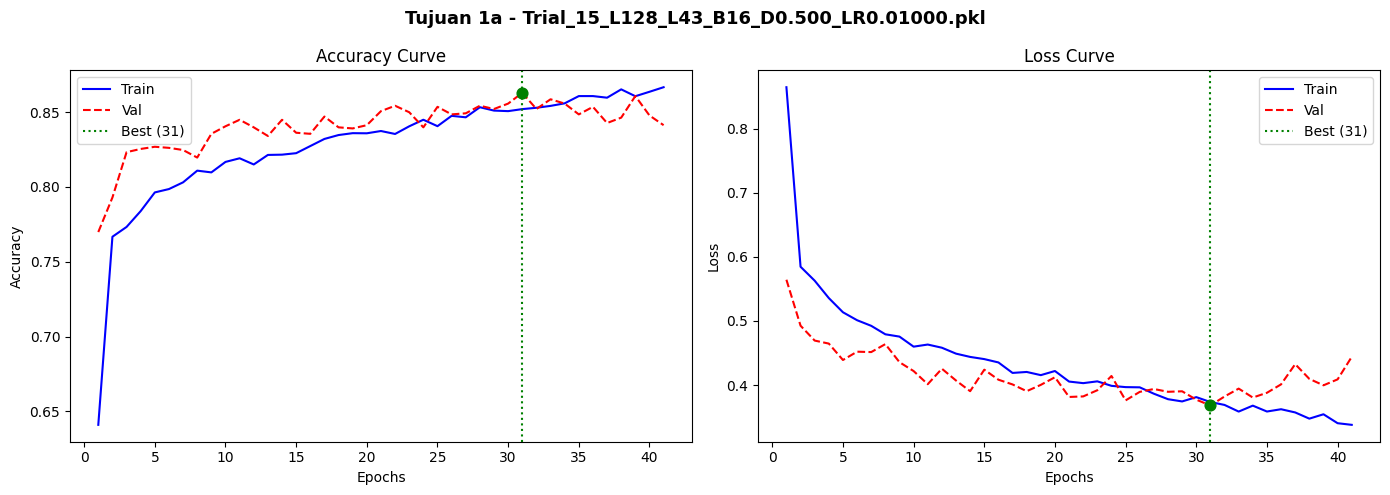

In [ ]:
# ── VISUALISASI LEARNING CURVE TRIAL TERPILIH ────────────────────────────────
BEST_TRIAL_HISTORY = 'Trial_15_L128_L43_B16_D0.500_LR0.01000.pkl'  # <-- sesuaikan

path_h = os.path.join(T1A_DIR_HISTORY, BEST_TRIAL_HISTORY)
if os.path.exists(path_h):
    with open(path_h, 'rb') as f:
        h = pickle.load(f)
    lc_path = os.path.join(T1A_BASE_DIR, f"LearningCurve_{BEST_TRIAL_HISTORY.replace('.pkl','.png')}")
    plot_learning_curve(h, f"Tujuan 1a - {BEST_TRIAL_HISTORY}", save_path=lc_path)

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8750    0.8203    0.8468       256
Vegetatif Akhir     0.7937    0.8380    0.8152       179
      Generatif     0.9055    0.8646    0.8845       288
          Panen     0.8559    0.8707    0.8632       232
Persiapan Lahan     0.8291    0.8321    0.8306       274
           Bera     0.7485    0.8153    0.7805       157

       accuracy                         0.8420      1386
      macro avg     0.8346    0.8402    0.8368      1386
   weighted avg     0.8442    0.8420    0.8426      1386

Test Accuracy : 84.1991%
Cohen's Kappa : 0.8090


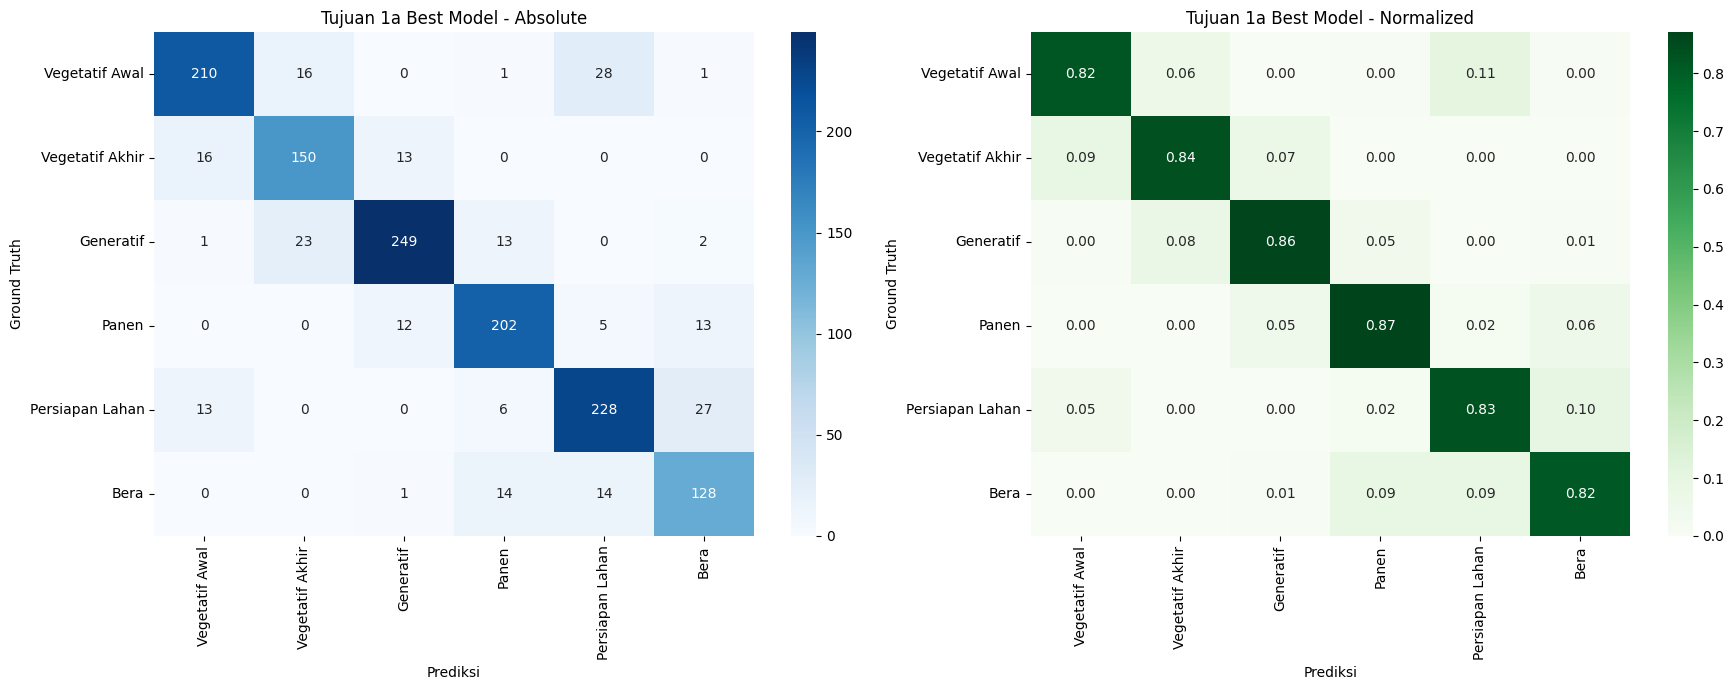

In [ ]:
# ── EVALUASI MODEL TERBAIK ───────────────────────────────────────────────────
BEST_TRIAL_MODEL = 'Trial_15_L128_L43_B16_D0.500_LR0.01000.keras'  # <-- sesuaikan

path_m = os.path.join(T1A_DIR_MODEL, BEST_TRIAL_MODEL)
if os.path.exists(path_m):
    model_best_1a = load_model(path_m, custom_objects={'subset_output': subset_output})
    evaluate_model(model_best_1a, X_test_sc, y_test, NAMA_KELAS,
                   title="Tujuan 1a Best Model", save_dir=T1A_BASE_DIR)

In [ ]:
# ── RINGKASAN ARSITEKTUR ────────────────────────────────────────────────────
model_best_1a.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 12, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 12, 256)        │       144,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 12, 86)         │       103,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 86)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 12, 43)         │         3,741 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 12, 6)          │           264 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Lambda)           │ (None, 6, 6)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 754,769 (2.88 MB)

 Trainable params: 251,589 (982.77 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 503,180 (1.92 MB)

In [ ]:
# ── VISUALISASI OPTUNA ───────────────────────────────────────────────────────
study = optuna.load_study(study_name=T1A_STUDY_NAME, storage=f"sqlite:///{T1A_PATH_DB}")

plots = {
    'Plot1_Optimization_History' : vis.plot_optimization_history(study),
    'Plot2_Parameter_Importance' : vis.plot_param_importances(study),
    'Plot3_Slice_Params'         : vis.plot_slice(study),
    'Plot4_Contour_LSTM_LR'      : vis.plot_contour(study, params=['lstm_units_1', 'learning_rate']),
    'Plot5_Contour_LR_Dropout'   : vis.plot_contour(study, params=['learning_rate', 'dropout_rate']),
    'Plot6_Contour_LSTM_Layers'  : vis.plot_contour(study, params=['lstm_units_1', 'lstm_units_2']),
}
for name, fig in plots.items():
    fig.write_html(os.path.join(T1A_BASE_DIR, f'{name}.html'))
    fig.show()


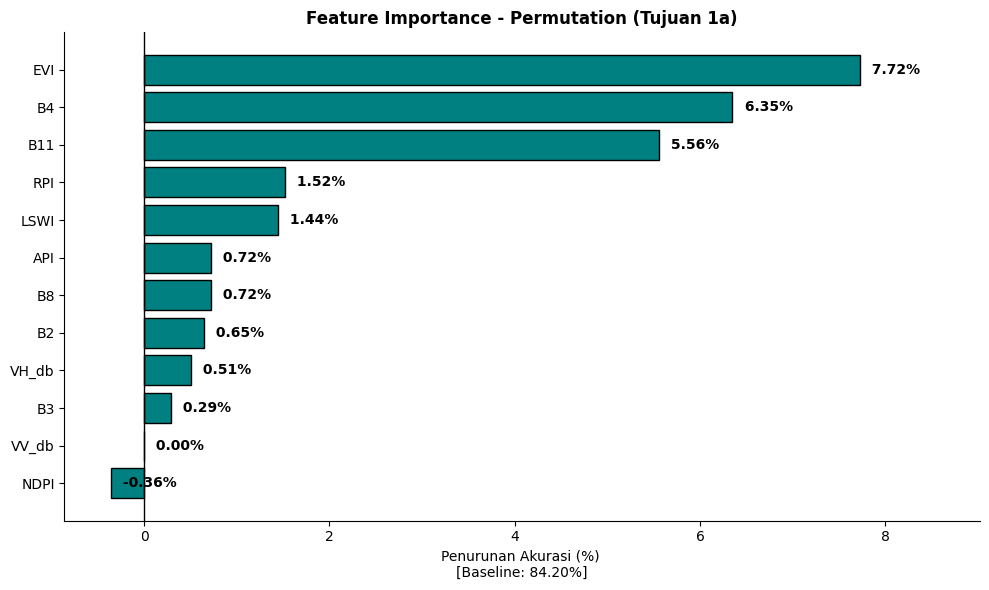

In [ ]:
# ── FEATURE IMPORTANCE (PERMUTATION) ────────────────────────────────────────
def permutation_importance(model, X_test, y_test, features):
    y_true   = y_test.argmax(axis=2).flatten()
    baseline = accuracy_score(y_true, model.predict(X_test, verbose=0).argmax(axis=2).flatten())
    results  = {}
    for i, feat in enumerate(features):
        X_perm = X_test.copy()
        np.random.seed(42)
        # np.random.shuffle(X_perm[:, :, i])
        acak_idx = np.random.permutation(len(X_perm))
        X_perm[:, :, i] = X_perm[acak_idx, :, i]
        perm_acc = accuracy_score(y_true, model.predict(X_perm, verbose=0).argmax(axis=2).flatten())
        results[feat] = baseline - perm_acc
    return results, baseline

if 'model_best_1a' in dir():
    feat_imp, baseline_acc = permutation_importance(
        model_best_1a, X_test_sc, y_test, CONFIG['features']
    )

    sorted_imp = dict(sorted(feat_imp.items(), key=lambda x: x[1], reverse=True))
    labels     = list(sorted_imp.keys())
    values_pct = [v * 100 for v in sorted_imp.values()]

    plt.figure(figsize=(10, 6))
    bars = plt.barh(labels, values_pct, color='teal', edgecolor='black')
    plt.xlim(min(values_pct) - 0.5, max(values_pct) + 1.3)
    plt.axvline(0, color='black', lw=1)
    plt.xlabel(f'Penurunan Akurasi (%) \n[Baseline: {baseline_acc*100:.2f}%]')
    plt.title('Feature Importance - Permutation (Tujuan 1a)', fontweight='bold')
    plt.gca().invert_yaxis()
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.grid(False)
    for bar in bars:
        w = bar.get_width()
        plt.text(w + (max(values_pct)*0.01), bar.get_y() + bar.get_height()/2,
                 f' {w:.2f}%', va='center', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(T1A_BASE_DIR, 'Feature_Importance_Final_1.png'), dpi=150)
    plt.show()


---
# Tujuan 1b: Arsitektur LSTM — Thorp & Drajat (Asli)

In [ ]:
# ── KONFIGURASI TUJUAN 1b ────────────────────────────────────────────────────
T1B_NAMA          = "Model Thorp [ASLI]"
T1B_UNITS         = 750
T1B_BATCH_SIZE    = 16
T1B_EPOCHS        = 20
T1B_LEARNING_RATE = 0.001

T1B_BASE_DIR     = os.path.join(CONFIG["root_dir"], T1B_NAMA)
T1B_PATH_MODEL   = os.path.join(T1B_BASE_DIR, 'Best_Model_LSTM_Thorp_Asli.keras')
T1B_PATH_HISTORY = os.path.join(T1B_BASE_DIR, 'History_LSTM_Thorp_Asli.pkl')
T1B_PATH_EXCEL   = os.path.join(T1B_BASE_DIR, 'Rekap_LSTM_Thorp_Asli.xlsx')

os.makedirs(T1B_BASE_DIR, exist_ok=True)

In [ ]:
# ── ARSITEKTUR LSTM (THORP) ─────────────────────────────────
def build_lstm_thorp(input_shape, num_classes, units, learning_rate, optimizer):
    inputs = Input(shape=input_shape)
    x = LSTM(units, return_sequences=True, activation='tanh',
             recurrent_activation='sigmoid')(inputs)
    x = TimeDistributed(Dense(num_classes, activation='softmax'))(x)
    outputs = Lambda(subset_output, name='output_layer')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=optimizer(learning_rate),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [ ]:
# ── TRAINING TUJUAN 1b ───────────────────────────────────────────────────────
K.clear_session(); set_seed(42)

# Training
model_thorp = build_lstm_thorp(
    input_shape=(X_train_sc.shape[1], X_train_sc.shape[2]),
    num_classes=y_train.shape[2],
    units=T1B_UNITS,
    learning_rate=T1B_LEARNING_RATE,
    optimizer=RMSprop
)
model_thorp.summary()

# Early Stopping
# es_1b = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

# Model checkpoint
mc_1b = ModelCheckpoint(T1B_PATH_MODEL, monitor='val_loss', save_best_only=True, verbose=0)

# Durasi
start_time = time.time()
history_1b = model_thorp.fit(
    X_train_sc, y_train,
    validation_data=(X_val_sc, y_val),
    epochs=T1B_EPOCHS, batch_size=T1B_BATCH_SIZE,
    callbacks=[mc_1b], verbose=1
)
duration_1b = time.time() - start_time

with open(T1B_PATH_HISTORY, 'wb') as f:
    pickle.dump(history_1b.history, f)

# Metrik Terbaik
best_idx_1b  = np.argmin(history_1b.history['val_loss'])
row_1b = {
    'Model'         : T1B_NAMA,
    'LSTM Units'    : T1B_UNITS,
    'Batch Size'    : T1B_BATCH_SIZE,
    'Learning Rate' : T1B_LEARNING_RATE,
    'Optimizer'     : 'RMSprop',
    'Val Loss'      : history_1b.history['val_loss'][best_idx_1b],
    'Val Acc'       : history_1b.history['val_accuracy'][best_idx_1b],
    'Train Loss'    : history_1b.history['loss'][best_idx_1b],
    'Train Acc'     : history_1b.history['accuracy'][best_idx_1b],
    'Best Epoch'    : best_idx_1b + 1,
    'Stop Epoch'    : len(history_1b.history['loss']),
    'Duration (s)'  : round(duration_1b, 2),
}

# Simpan Ke Excel
pd.DataFrame([row_1b]).to_excel(T1B_PATH_EXCEL, index=False)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 12, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 12, 750)        │     2,289,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 12, 6)          │         4,506 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Lambda)           │ (None, 6, 6)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,293,506 (8.75 MB)

 Trainable params: 2,293,506 (8.75 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 26s 209ms/step - accuracy: 0.5644 - loss: 1.1432 - val_accuracy: 0.6688 - val_loss: 0.8901
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 25s 217ms/step - accuracy: 0.6853 - loss: 0.7991 - val_accuracy: 0.7157 - val_loss: 0.7422
Epoch 3/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 40s 211ms/step - accuracy: 0.7214 - loss: 0.6905 - val_accuracy: 0.7496 - val_loss: 0.6475
Epoch 4/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 43s 234ms/step - accuracy: 0.7429 - loss: 0.6411 - val_accuracy: 0.7619 - val_loss: 0.6066
Epoch 5/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 25s 213ms/step - accuracy: 0.7551 - loss: 0.6126 - val_accuracy: 0.7727 - val_loss: 0.5860
Epoch 6/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 39s 199ms/step - accuracy: 0.7632 - loss: 0.5949 - val_accuracy: 0.7799 - val_loss: 0.5747
Epoch 7/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 26s 223ms/step - accuracy: 0.7674 - loss: 0.5827 - val_accuracy: 0.7828 - val_loss: 0.5671
Epoch 8/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 26s 222ms/step - accuracy: 0.7700 - loss: 0

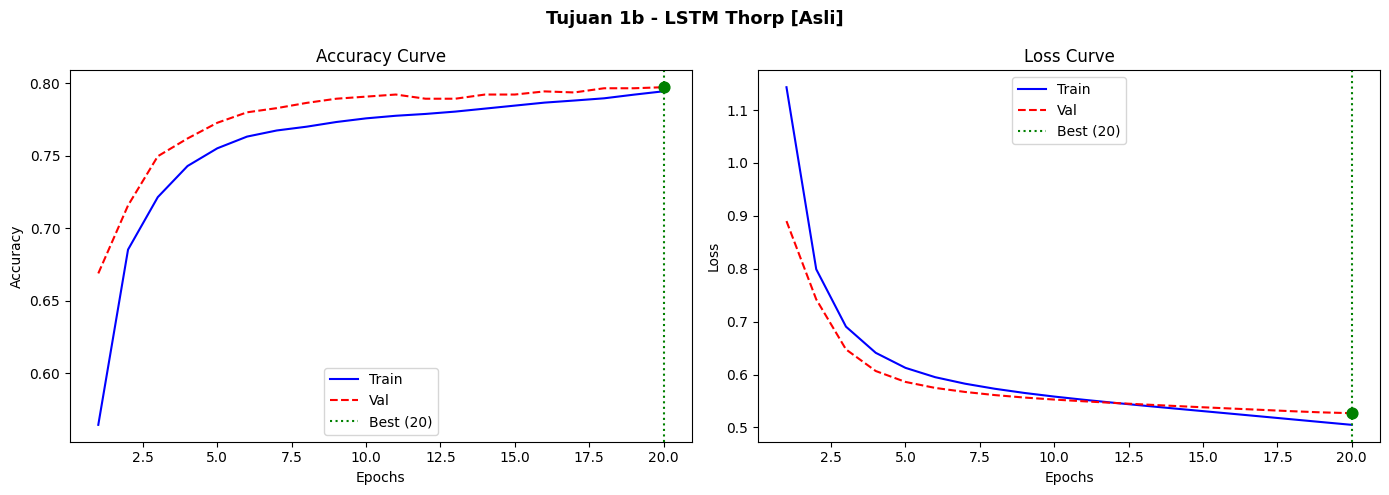

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8571    0.6562    0.7434       256
Vegetatif Akhir     0.7651    0.7095    0.7362       179
      Generatif     0.8218    0.8646    0.8426       288
          Panen     0.7801    0.8103    0.7949       232
Persiapan Lahan     0.7157    0.7993    0.7552       274
           Bera     0.6897    0.7643    0.7251       157

       accuracy                         0.7727      1386
      macro avg     0.7716    0.7674    0.7662      1386
   weighted avg     0.7781    0.7727    0.7720      1386

Test Accuracy : 77.2727%
Cohen's Kappa : 0.7249


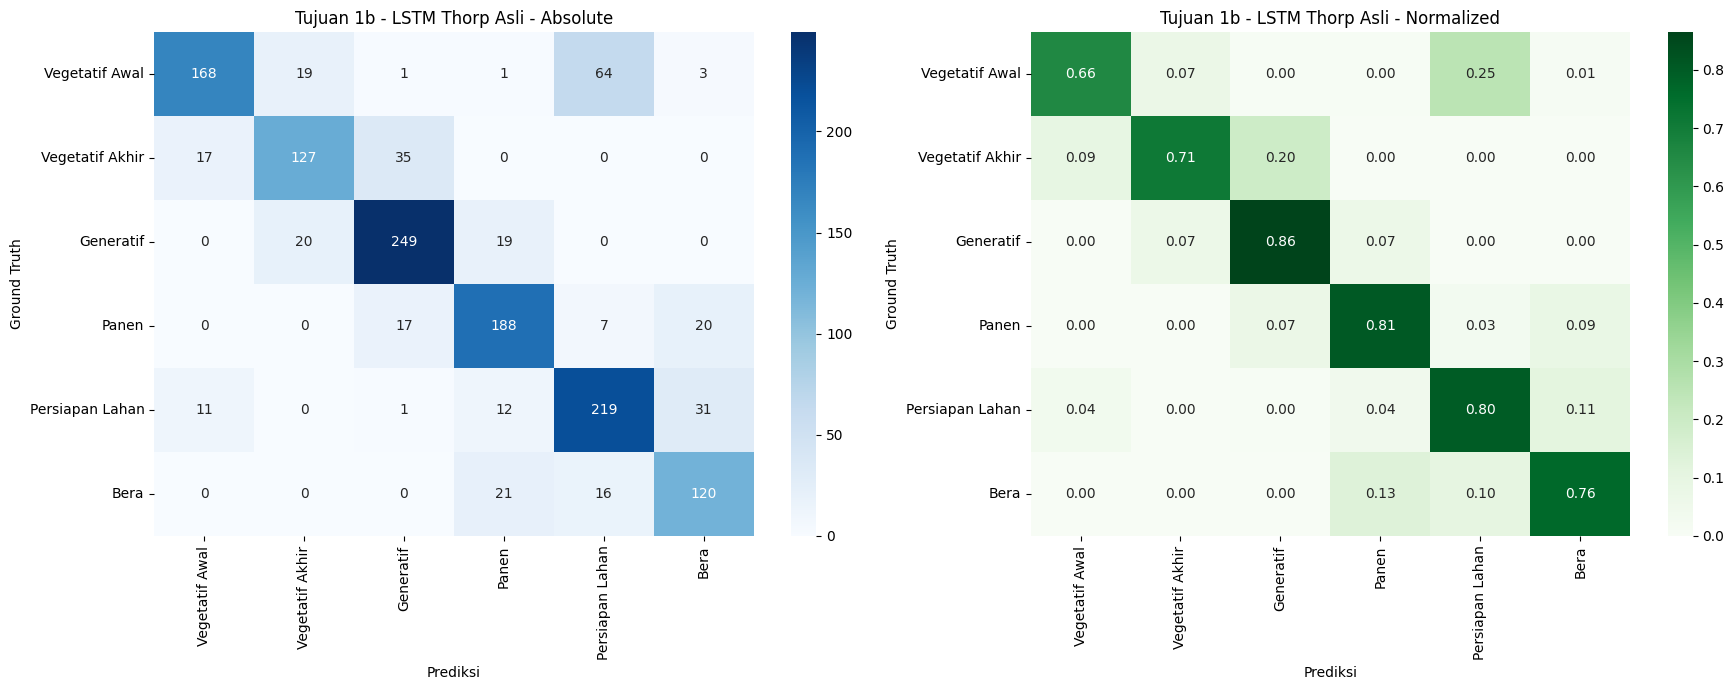

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 12, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 12, 750)        │     2,289,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 12, 6)          │         4,506 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Lambda)           │ (None, 6, 6)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,587,014 (17.50 MB)

 Trainable params: 2,293,506 (8.75 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,293,508 (8.75 MB)

In [ ]:
# ── EVALUASI TUJUAN 1b ───────────────────────────────────────────────────────
with open(T1B_PATH_HISTORY, 'rb') as f:
    h_1b = pickle.load(f)

# Learning curve
plot_learning_curve(h_1b, "Tujuan 1b - LSTM Thorp [Asli]",
                    save_path=os.path.join(T1B_BASE_DIR, 'LearningCurve.png'))

# Evaluasi Model
model_1b_best = load_model(T1B_PATH_MODEL, custom_objects={'subset_output': subset_output})
evaluate_model(model_1b_best, X_test_sc, y_test, NAMA_KELAS,
               title="Tujuan 1b - LSTM Thorp Asli", save_dir=T1B_BASE_DIR)

# Arsitektur
model_1b_best.summary()

# Tujuan 1c: Arsitektur LSTM — Thorp & Drajat (Fixed)
> Menggunakan hyperparameter yang sama dengan Tujuan 1a (hasil Optuna)

In [ ]:
# ── KONFIGURASI TUJUAN 1c ────────────────────────────────────────────────────
# Hyperparameter = hasil terbaik dari Tujuan 1a (Optuna)
T1C_NAMA         = "Model Thorp [TUNING BI-LSTM]"
T1C_UNITS        = 128      # Gunakan best lstm_units_1 dari Tujuan 1a
T1C_BATCH_SIZE   = 16      # Gunakan best batch_size dari Tujuan 1a
T1C_EPOCHS       = 100
T1C_PATIENCE     = 10
T1C_LEARNING_RATE = 0.01   # Gunakan best learning_rate dari Tujuan 1a

T1C_BASE_DIR     = os.path.join(CONFIG["root_dir"], T1C_NAMA)
T1C_PATH_MODEL   = os.path.join(T1C_BASE_DIR, 'Best_Model_LSTM_Thorp_Fixed.keras')
T1C_PATH_HISTORY = os.path.join(T1C_BASE_DIR, 'History_LSTM_Thorp_Fixed.pkl')
T1C_PATH_EXCEL   = os.path.join(T1C_BASE_DIR, 'Rekap_LSTM_Thorp_Fixed.xlsx')

os.makedirs(T1C_BASE_DIR, exist_ok=True)

In [ ]:
# ── TRAINING TUJUAN 1c ───────────────────────────────────────────────────────
K.clear_session(); set_seed(42)
# Bangun Model
model_1c = build_lstm_thorp((12, X_train_sc.shape[2]), y_train.shape[2],
                              T1C_UNITS, T1C_LEARNING_RATE, optimizer=tf.keras.optimizers.Adam)

# Early Stopping
es_1c = EarlyStopping(monitor='val_loss', patience=T1C_PATIENCE,
                      restore_best_weights=True, verbose=0)
# Model Checkpoint
mc_1c = ModelCheckpoint(T1C_PATH_MODEL, monitor='val_loss',
                        save_best_only=True, verbose=0)

# Durasi
start_time = time.time()
history_1c = model_1c.fit(
    X_train_sc, y_train,
    validation_data=(X_val_sc, y_val),
    epochs=T1C_EPOCHS, batch_size=T1C_BATCH_SIZE,
    callbacks=[es_1c, mc_1c], verbose=1
)
duration_1c = time.time() - start_time

with open(T1C_PATH_HISTORY, 'wb') as f:
    pickle.dump(history_1c.history, f)

# Mencatat Metrik Terbaik
best_idx = np.argmin(history_1c.history['val_loss'])
df_1c = pd.DataFrame([{
    'LSTM Units': T1C_UNITS,
    'Batch Size': T1C_BATCH_SIZE,
    'Learning Rate': T1C_LEARNING_RATE,
    'Optimizer': 'Adam',
    'Best Epoch': best_idx + 1,
    'Stop Epoch': len(history_1c.history['loss']),
    'Val Accuracy': history_1c.history['val_accuracy'][best_idx],
    'Val Loss': history_1c.history['val_loss'][best_idx],
    'Train Accuracy': history_1c.history['accuracy'][best_idx],
    'Train Loss': history_1c.history['loss'][best_idx],
    'Training Time (s)': round(duration_1c, 2),
    'Training Time (m)': round(duration_1c/60, 2),
}])
df_1c.to_excel(T1C_PATH_EXCEL, index=False)
print(f"Training selesai ({duration_1c/60:.1f} menit)")
display(df_1c)

Epoch 1/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.6548 - loss: 0.8596 - val_accuracy: 0.7475 - val_loss: 0.6263
Epoch 2/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7583 - loss: 0.6011 - val_accuracy: 0.7590 - val_loss: 0.5999
Epoch 3/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7607 - loss: 0.5804 - val_accuracy: 0.7778 - val_loss: 0.5506
Epoch 4/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7711 - loss: 0.5553 - val_accuracy: 0.7792 - val_loss: 0.5635
Epoch 5/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7756 - loss: 0.5412 - val_accuracy: 0.7778 - val_loss: 0.5560
Epoch 6/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7830 - loss: 0.5225 - val_accuracy: 0.7857 - val_loss: 0.5389
Epoch 7/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7940 - loss: 0.5071 - val_accuracy: 0.7879 - val_loss: 0.5341
Epoch 8/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8002 - loss: 0.4909 - val_a

,LSTM Units,Batch Size,Learning Rate,Optimizer,Best Epoch,Stop Epoch,Val Accuracy,Val Loss,Train Accuracy,Train Loss,Training Time (s),Training Time (m)
0,128,16,0.01,Adam,12,22,0.79798,0.498464,0.811153,0.459975,25.68,0.43


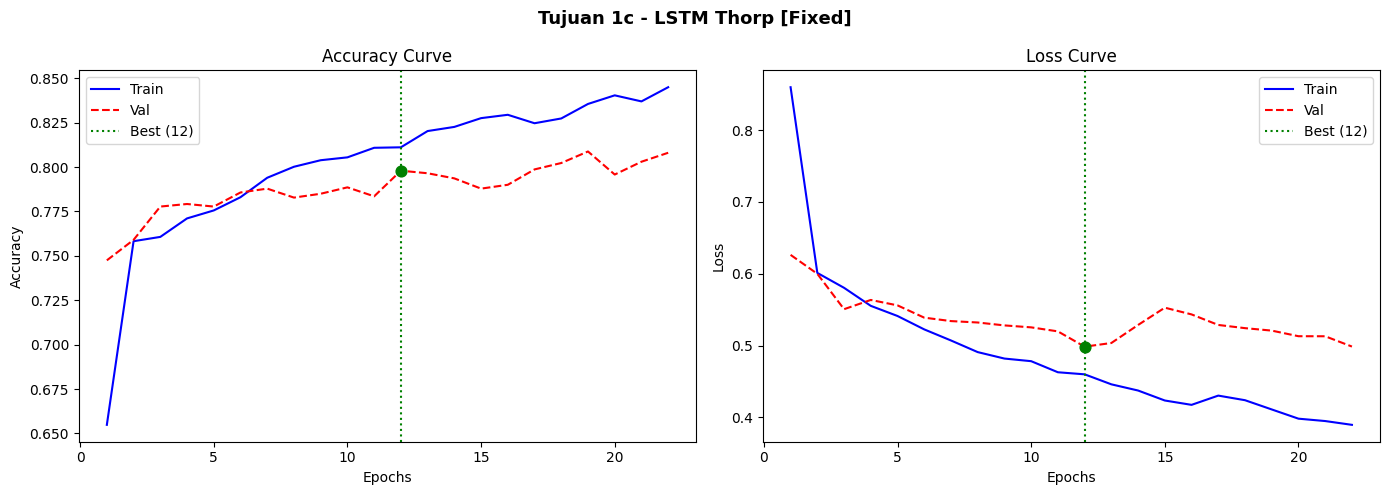

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8054    0.8086    0.8070       256
Vegetatif Akhir     0.7385    0.8045    0.7701       179
      Generatif     0.8714    0.8472    0.8592       288
          Panen     0.8167    0.8448    0.8305       232
Persiapan Lahan     0.7962    0.7701    0.7829       274
           Bera     0.7852    0.7452    0.7647       157

       accuracy                         0.8074      1386
      macro avg     0.8022    0.8034    0.8024      1386
   weighted avg     0.8083    0.8074    0.8075      1386

Test Accuracy : 80.7359%
Cohen's Kappa : 0.7670


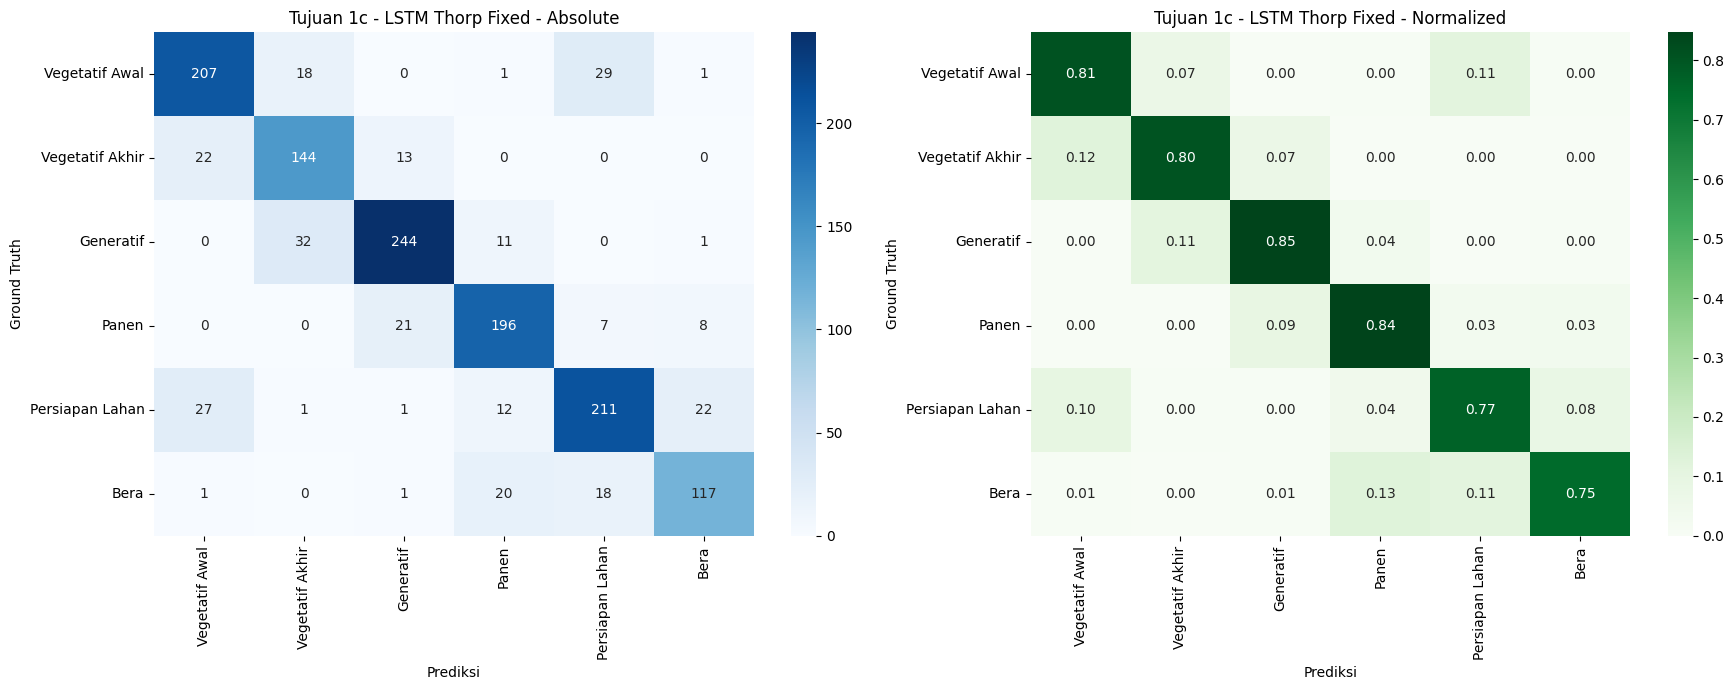

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 12, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 12, 128)        │        72,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 12, 6)          │           774 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Lambda)           │ (None, 6, 6)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,900 (855.08 KB)

 Trainable params: 72,966 (285.02 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 145,934 (570.06 KB)

In [ ]:
# ── EVALUASI TUJUAN 1c ───────────────────────────────────────────────────────
with open(T1C_PATH_HISTORY, 'rb') as f:
    h_1c = pickle.load(f)

# Learning Curve
plot_learning_curve(h_1c, "Tujuan 1c - LSTM Thorp [Fixed]",
                    save_path=os.path.join(T1C_BASE_DIR, 'LearningCurve.png'))

# Evaluasi Model
model_1c_best = load_model(T1C_PATH_MODEL, custom_objects={'subset_output': subset_output})
evaluate_model(model_1c_best, X_test_sc, y_test, NAMA_KELAS,
               title="Tujuan 1c - LSTM Thorp Fixed", save_dir=T1C_BASE_DIR)

# Arsitektur
model_1c_best.summary()

MC Necmar Test

In [ ]:
!pip install tensorflow optuna statsmodels -q

In [ ]:
# ── UJI MCNEMAR: PERBANDINGAN SIGNIFIKANSI STATISTIK ANTAR MODEL ────────────
# Membandingkan model tersimpan (.keras) tanpa training ulang.
# H0: kedua model memiliki proporsi error yang sama pada test set.
from statsmodels.stats.contingency_tables import mcnemar

def load_saved_models():
    """Load ketiga model terbaik (Tujuan 1a, 1b, 1c) dari checkpoint .keras."""
    paths = {
        '1a (Bi-LSTM Peneliti)': os.path.join(T1A_DIR_MODEL, BEST_TRIAL_MODEL),
        '1b (LSTM Thorp Asli)' : T1B_PATH_MODEL,
        '1c (LSTM Thorp Fixed)': T1C_PATH_MODEL,
    }
    models = {}
    for name, p in paths.items():
        if not os.path.exists(p):
            raise FileNotFoundError(f"Model '{name}' tidak ditemukan: {p}")
        models[name] = load_model(p, custom_objects={'subset_output': subset_output})
    return models

def get_predictions(model, X_test, y_test):
    """Prediksi per-timestep, di-flatten selaras dengan evaluate_model()."""
    y_pred = model.predict(X_test, verbose=0).argmax(axis=2).flatten()
    y_true = y_test.argmax(axis=2).flatten()
    return y_true, y_pred

def run_mcnemar(y_true, pred_a, pred_b, name_a, name_b):
    """
    Bangun contingency table 2x2 lalu jalankan McNemar (exact bila n01+n10 < 25,
    sesuai rekomendasi umum untuk sampel kecil; correction=True untuk kasus lain).
    """
    correct_a = (pred_a == y_true)
    correct_b = (pred_b == y_true)

    n11 = np.sum(correct_a & correct_b)    # kedua model benar
    n10 = np.sum(correct_a & ~correct_b)   # A benar, B salah
    n01 = np.sum(~correct_a & correct_b)   # A salah, B benar
    n00 = np.sum(~correct_a & ~correct_b)  # kedua model salah

    table = [[n11, n10], [n01, n00]]
    use_exact = (n10 + n01) < 25
    result = mcnemar(table, exact=use_exact, correction=not use_exact)

    print(f"\n{'='*65}\nMcNemar Test: {name_a}  vs  {name_b}\n{'='*65}")
    print(f"Contingency Table (n10={n10}, n01={n01}, n11={n11}, n00={n00})")
    print(f"Metode       : {'Exact binomial' if use_exact else 'Chi-square (dengan koreksi kontinuitas)'}")
    print(f"Statistic    : {result.statistic:.4f}")
    print(f"p-value      : {result.pvalue:.6f}")
    alpha = 0.05
    verdict = "SIGNIFIKAN" if result.pvalue < alpha else "TIDAK signifikan"
    print(f"Kesimpulan   : Perbedaan performa {verdict} pada α={alpha} "
          f"({'tolak' if result.pvalue < alpha else 'gagal tolak'} H0)")
    return {'Model A': name_a, 'Model B': name_b, 'n10': n10, 'n01': n01,
            'Statistic': result.statistic, 'p-value': result.pvalue,
            'Signifikan (α=0.05)': result.pvalue < alpha}

# ── EKSEKUSI ──────────────────────────────────────────────────────────────
models = load_saved_models()
preds = {name: get_predictions(m, X_test_sc, y_test) for name, m in models.items()}

pairs = [
    ('1a (Bi-LSTM Peneliti)', '1b (LSTM Thorp Asli)'),
    ('1a (Bi-LSTM Peneliti)', '1c (LSTM Thorp Fixed)'),
    ('1b (LSTM Thorp Asli)',  '1c (LSTM Thorp Fixed)'),
]

rekap_mcnemar = []
y_true_ref = preds[pairs[0][0]][0]  # y_true identik untuk semua model (test set sama)
for name_a, name_b in pairs:
    _, pred_a = preds[name_a]
    _, pred_b = preds[name_b]
    rekap_mcnemar.append(run_mcnemar(y_true_ref, pred_a, pred_b, name_a, name_b))

df_mcnemar = pd.DataFrame(rekap_mcnemar)
display(df_mcnemar)

# Simpan rekap ke Excel untuk lampiran skripsi
mcnemar_path = os.path.join(CONFIG["root_dir"], 'Rekap_McNemar_Test.xlsx')
df_mcnemar.to_excel(mcnemar_path, index=False)
print(f"\nRekap tersimpan: {mcnemar_path}")


McNemar Test: 1a (Bi-LSTM Peneliti)  vs  1b (LSTM Thorp Asli)
Contingency Table (n10=156, n01=60, n11=1011, n00=159)
Metode       : Chi-square (dengan koreksi kontinuitas)
Statistic    : 41.7824
p-value      : 0.000000
Kesimpulan   : Perbedaan performa SIGNIFIKAN pada α=0.05 (tolak H0)

McNemar Test: 1a (Bi-LSTM Peneliti)  vs  1c (LSTM Thorp Fixed)
Contingency Table (n10=115, n01=67, n11=1052, n00=152)
Metode       : Chi-square (dengan koreksi kontinuitas)
Statistic    : 12.1374
p-value      : 0.000494
Kesimpulan   : Perbedaan performa SIGNIFIKAN pada α=0.05 (tolak H0)

McNemar Test: 1b (LSTM Thorp Asli)  vs  1c (LSTM Thorp Fixed)
Contingency Table (n10=70, n01=118, n11=1001, n00=197)
Metode       : Chi-square (dengan koreksi kontinuitas)
Statistic    : 11.7500
p-value      : 0.000608
Kesimpulan   : Perbedaan performa SIGNIFIKAN pada α=0.05 (tolak H0)


,Model A,Model B,n10,n01,Statistic,p-value,Signifikan (α=0.05)
0,1a (Bi-LSTM Peneliti),1b (LSTM Thorp Asli),156,60,41.782407,1.020172e-10,True
1,1a (Bi-LSTM Peneliti),1c (LSTM Thorp Fixed),115,67,12.137363,4.942162e-04,True
2,1b (LSTM Thorp Asli),1c (LSTM Thorp Fixed),70,118,11.750000,6.084324e-04,True



Rekap tersimpan: /content/drive/MyDrive/Skripsi/05. Modeliling with Winsorizing/Rekap_McNemar_Test.xlsx


---
# Tujuan 2: Ablasi Skenario Fitur — Arsitektur Bi-LSTM
> Menggunakan **hyperparameter terbaik dari Tujuan 1a** dan **data split yang sama**

In [11]:
# ── KONFIGURASI TUJUAN 2 ────────────────────────────────────────────────────
T2_LSTM_UNITS_1  = 128
T2_LSTM_UNITS_2  = 43
T2_BATCH_SIZE    = 16
T2_DROPOUT       = 0.5
T2_LEARNING_RATE = 0.01
T2_EPOCHS        = 100
T2_PATIENCE      = 10

T2_NAMA      = "Perbandingan Skenario"
T2_BASE_DIR  = os.path.join(CONFIG["root_dir"], T2_NAMA)
T2_DIR_MODEL = os.path.join(T2_BASE_DIR, 'Model Skenario')
T2_DIR_HISTORY = os.path.join(T2_BASE_DIR, 'History Skenario')
T2_PATH_EXCEL  = os.path.join(T2_BASE_DIR, 'Hasil_Skenario_Fitur.xlsx')

for d in [T2_DIR_MODEL, T2_DIR_HISTORY]:
    os.makedirs(d, exist_ok=True)

# Definisi skenario fitur
# Urutan fitur CONFIG: [VV, VH, RPI, NDPI, API, B2, B3, B4, B8, B11, EVI, LSWI]
T2_SCENARIOS = {
    "1. Sentinel-1 Bands Only"           : [0, 1],
    "2. Sentinel-1 Indeks Only"          : [2, 3, 4],
    "3. Sentinel-1 Complete"             : [0, 1, 2, 3, 4],
    "4. Sentinel-2 Bands Only"           : [5, 6, 7, 8, 9],
    "5. Sentinel-2 Indeks Only"          : [10, 11],
    "6. Sentinel-2 Complete"             : [5, 6, 7, 8, 9, 10, 11],
    "7. Sentinel-1 + Sentinel-2 Band"    : [0, 1, 5, 6, 7, 8, 9],
    "8. Sentinel-1 + Sentinel-2 Indeks"  : [2, 3, 4, 10, 11],
    "9. Sentinel-1 + Sentinel-2 Complete": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
}

print(f"Tujuan 2 menggunakan {len(T2_SCENARIOS)} skenario fitur.")
print(f"Hyperparameter: LSTM=({T2_LSTM_UNITS_1},{T2_LSTM_UNITS_2}), "
      f"Batch={T2_BATCH_SIZE}, Drop={T2_DROPOUT:.4f}, LR={T2_LEARNING_RATE}")


Tujuan 2 menggunakan 9 skenario fitur.
Hyperparameter: LSTM=(128,43), Batch=16, Drop=0.5000, LR=0.01


In [12]:
# ── EKSEKUSI TRAINING SEMUA SKENARIO ────────────────────────────────────────
results_t2 = []

for name, feat_idx in T2_SCENARIOS.items():
    print(f"\nSkenario: {name} | Fitur: {feat_idx}")

    # import tf
    import gc
    tf.keras.backend.clear_session()
    set_seed(42)
    gc.collect()

    # Slicing Data
    X_tr = X_train_sc[:, :, feat_idx]
    X_va = X_val_sc[:, :, feat_idx]
    X_te = X_test_sc[:, :, feat_idx]

    # Bangun Model
    model = build_bilstm(
        input_shape=(X_tr.shape[1], X_tr.shape[2]),
        num_classes=y_train.shape[2],
        lstm_units_1=T2_LSTM_UNITS_1, lstm_units_2=T2_LSTM_UNITS_2,
        dropout_rate=T2_DROPOUT, learning_rate=T2_LEARNING_RATE
    )

    # Nama file
    safe_name    = name.replace(" ", "_").replace(".", "").replace("-", "")
    path_model   = os.path.join(T2_DIR_MODEL,   f"BestModel_{safe_name}.keras")
    path_history = os.path.join(T2_DIR_HISTORY, f"History_{safe_name}.pkl")

    # Early Stopping
    es = EarlyStopping(monitor='val_loss', patience=T2_PATIENCE,
                       restore_best_weights=True, verbose=0)

    # Model Checkpoint
    mc = ModelCheckpoint(path_model, monitor='val_loss', save_best_only=True, verbose=0)

    try:
        # Durasi
        start_time = time.time()
        history = model.fit(
            X_tr, y_train,
            validation_data=(X_va, y_val),
            epochs=T2_EPOCHS, batch_size=T2_BATCH_SIZE,
            callbacks=[es, mc], verbose=0
        )
        duration = time.time() - start_time

        with open(path_history, 'wb') as f:
            pickle.dump(history.history, f)

        # Ambil metrik terbaik
        best_idx   = np.argmin(history.history['val_loss'])
        val_loss   = history.history['val_loss'][best_idx]
        val_acc    = history.history['val_accuracy'][best_idx]
        train_loss = history.history['loss'][best_idx]
        train_acc  = history.history['accuracy'][best_idx]
        epoch_stop = len(history.history['loss'])

        # Load best model untuk testing
        del model
        best_model = load_model(path_model, custom_objects={'subset_output': subset_output})
        test_loss, test_acc = best_model.evaluate(X_te, y_test, verbose=0)

        print(f"  ({duration/60:.1f} m) | Val Acc: {val_acc:.2%} | Test Acc: {test_acc:.2%}")

        results_t2.append({
            'Skenario'           : name,
            'Jumlah Fitur'       : len(feat_idx),
            'LSTM Units 1'       : T2_LSTM_UNITS_1,
            'LSTM Units 2'       : T2_LSTM_UNITS_2,
            'Batch Size'         : T2_BATCH_SIZE,
            'Dropout'            : T2_DROPOUT,
            'Learning Rate'      : T2_LEARNING_RATE,
            'Val Accuracy'       : val_acc,
            'Val Loss'           : val_loss,
            'Train Accuracy'     : train_acc,
            'Train Loss'         : train_loss,
            'Test Accuracy'      : test_acc,
            'Test Loss'          : test_loss,
            'Best Epoch'         : best_idx + 1,
            'Stop Epoch'         : epoch_stop,
            'Training Time (s)'  : round(duration, 2),
        })

    except Exception as e:
        print(f"  ERROR: {e}")

df_t2 = pd.DataFrame(results_t2).sort_values('Test Accuracy', ascending=False)
df_t2.to_excel(T2_PATH_EXCEL, index=False)
display(df_t2)
print(f"\nHasil disimpan: {T2_PATH_EXCEL}")


Skenario: 1. Sentinel-1 Bands Only | Fitur: [0, 1]
  (1.1 m) | Val Acc: 71.65% | Test Acc: 69.05%

Skenario: 2. Sentinel-1 Indeks Only | Fitur: [2, 3, 4]
  (1.1 m) | Val Acc: 71.07% | Test Acc: 67.75%

Skenario: 3. Sentinel-1 Complete | Fitur: [0, 1, 2, 3, 4]
  (1.1 m) | Val Acc: 71.50% | Test Acc: 70.92%

Skenario: 4. Sentinel-2 Bands Only | Fitur: [5, 6, 7, 8, 9]
  (1.4 m) | Val Acc: 84.56% | Test Acc: 84.20%

Skenario: 5. Sentinel-2 Indeks Only | Fitur: [10, 11]
  (1.6 m) | Val Acc: 84.20% | Test Acc: 83.84%

Skenario: 6. Sentinel-2 Complete | Fitur: [5, 6, 7, 8, 9, 10, 11]
  (2.0 m) | Val Acc: 86.44% | Test Acc: 84.78%

Skenario: 7. Sentinel-1 + Sentinel-2 Band | Fitur: [0, 1, 5, 6, 7, 8, 9]
  (1.6 m) | Val Acc: 85.93% | Test Acc: 83.62%

Skenario: 8. Sentinel-1 + Sentinel-2 Indeks | Fitur: [2, 3, 4, 10, 11]
  (0.9 m) | Val Acc: 83.84% | Test Acc: 82.68%

Skenario: 9. Sentinel-1 + Sentinel-2 Complete | Fitur: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
  (1.5 m) | Val Acc: 86.29% | Tes

,Skenario,Jumlah Fitur,LSTM Units 1,LSTM Units 2,Batch Size,Dropout,Learning Rate,Val Accuracy,Val Loss,Train Accuracy,Train Loss,Test Accuracy,Test Loss,Best Epoch,Stop Epoch,Training Time (s)
5,6. Sentinel-2 Complete,7,128,43,16,0.5,0.01,0.864358,0.378935,0.863596,0.345268,0.847763,0.378342,47,57,120.10
3,4. Sentinel-2 Bands Only,5,128,43,16,0.5,0.01,0.845599,0.401482,0.829202,0.414914,0.841991,0.375944,29,39,86.93
8,9. Sentinel-1 + Sentinel-2 Complete,12,128,43,16,0.5,0.01,0.862915,0.368227,0.852011,0.373580,0.841991,0.398461,31,41,90.48
4,5. Sentinel-2 Indeks Only,2,128,43,16,0.5,0.01,0.841991,0.405362,0.837284,0.411369,0.838384,0.397251,33,43,94.90
6,7. Sentinel-1 + Sentinel-2 Band,7,128,43,16,0.5,0.01,0.859307,0.385417,0.851203,0.373571,0.836219,0.390678,34,44,94.46
7,8. Sentinel-1 + Sentinel-2 Indeks,5,128,43,16,0.5,0.01,0.838384,0.412092,0.814475,0.469247,0.826840,0.408804,13,23,55.33
2,3. Sentinel-1 Complete,5,128,43,16,0.5,0.01,0.715007,0.703482,0.711746,0.704055,0.709235,0.696349,20,30,68.58
0,1. Sentinel-1 Bands Only,2,128,43,16,0.5,0.01,0.716450,0.719783,0.694684,0.745141,0.690476,0.746476,18,28,64.53
1,2. Sentinel-1 Indeks Only,3,128,43,16,0.5,0.01,0.710678,0.737893,0.700611,0.740504,0.677489,0.752565,19,29,68.36



Hasil disimpan: /content/drive/MyDrive/Skripsi/05. Modeliling with Winsorizing/Perbandingan Skenario/Hasil_Skenario_Fitur.xlsx



Skenario: 1. Sentinel-1 Bands Only


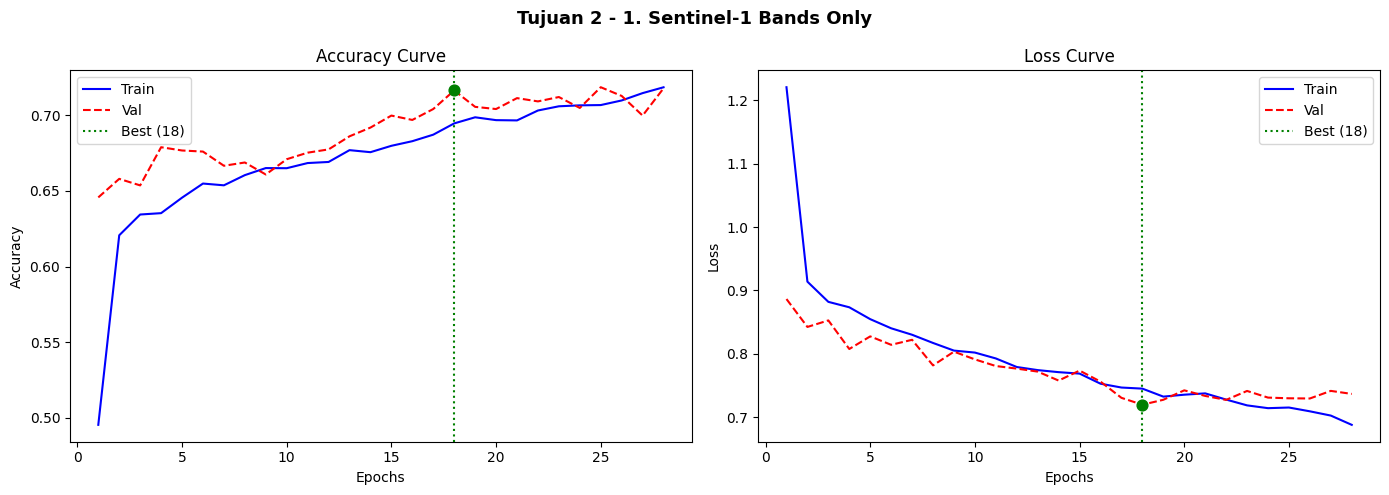

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8053    0.7109    0.7552       256
Vegetatif Akhir     0.7229    0.6704    0.6957       179
      Generatif     0.7565    0.7118    0.7335       288
          Panen     0.6102    0.6681    0.6379       232
Persiapan Lahan     0.7546    0.7409    0.7477       274
           Bera     0.4600    0.5860    0.5154       157

       accuracy                         0.6905      1386
      macro avg     0.6849    0.6814    0.6809      1386
   weighted avg     0.7027    0.6905    0.6947      1386

Test Accuracy : 69.0476%
Cohen's Kappa : 0.6264


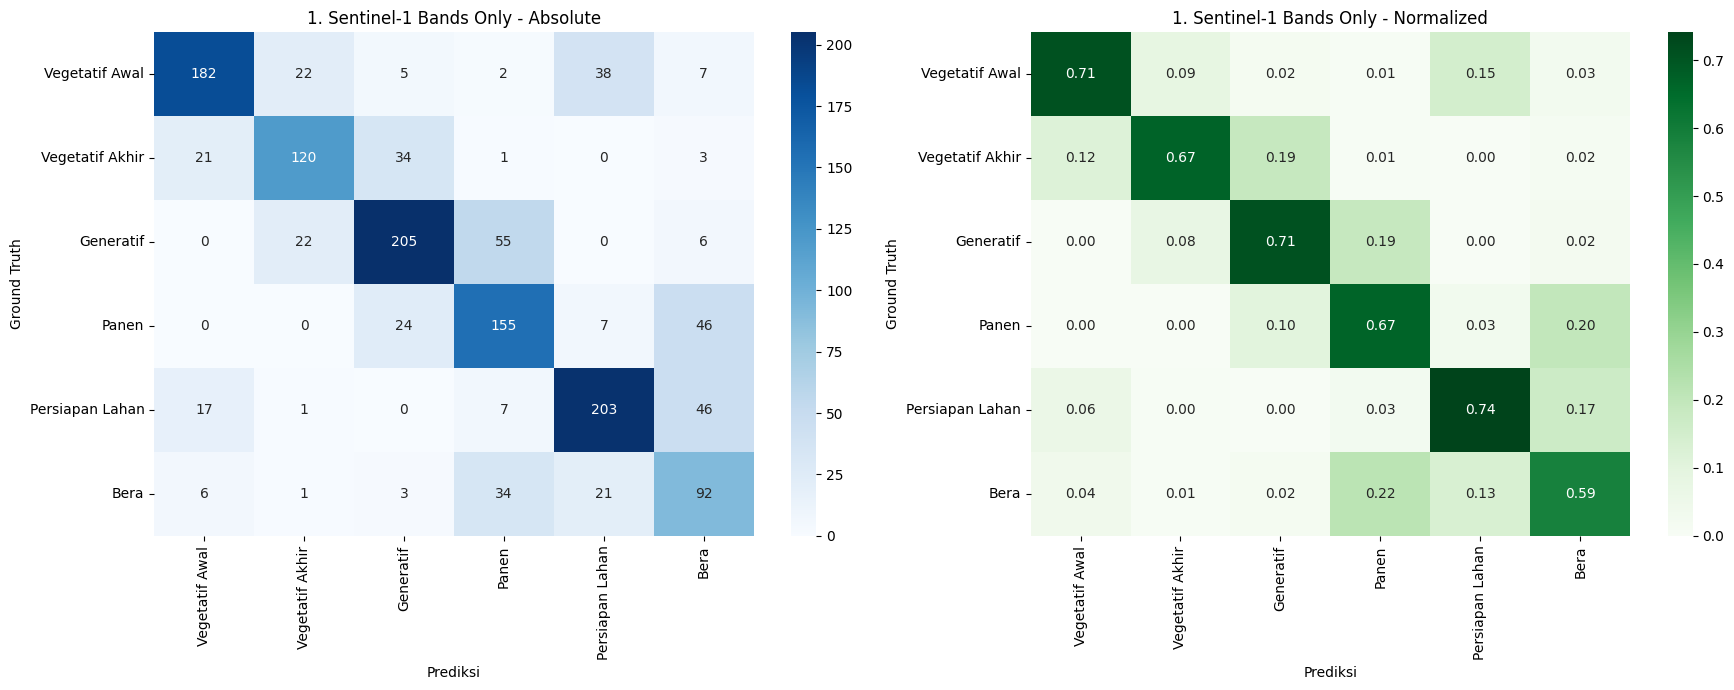


Skenario: 2. Sentinel-1 Indeks Only


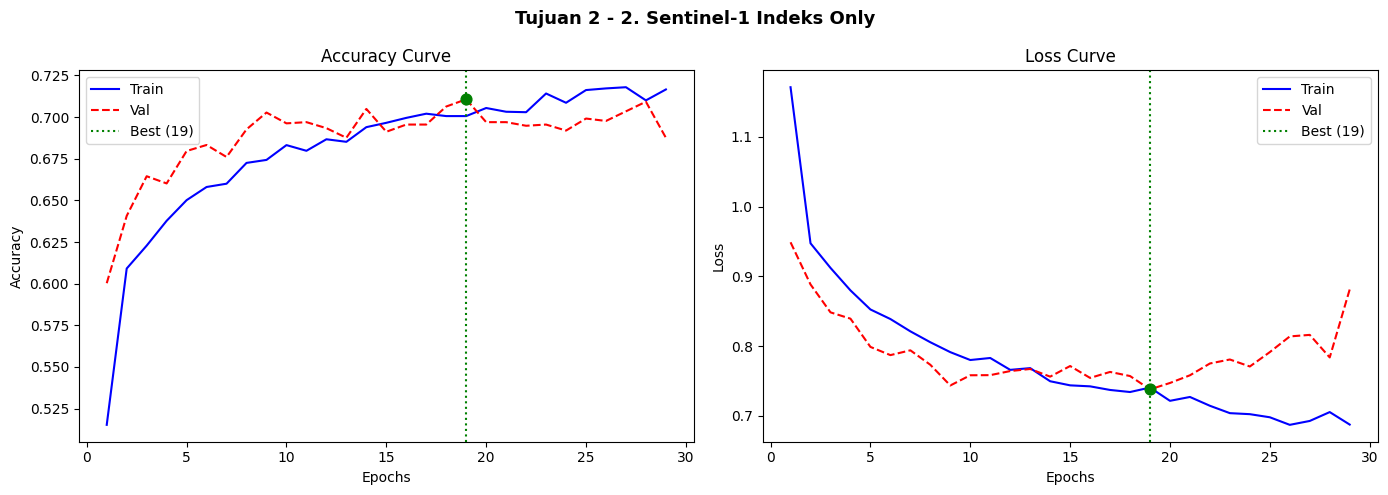

                 precision    recall  f1-score   support

 Vegetatif Awal     0.7480    0.7305    0.7391       256
Vegetatif Akhir     0.7134    0.6257    0.6667       179
      Generatif     0.7597    0.6806    0.7179       288
          Panen     0.6104    0.6552    0.6320       232
Persiapan Lahan     0.7063    0.7372    0.7214       274
           Bera     0.4839    0.5732    0.5248       157

       accuracy                         0.6775      1386
      macro avg     0.6703    0.6671    0.6670      1386
   weighted avg     0.6848    0.6775    0.6797      1386

Test Accuracy : 67.7489%
Cohen's Kappa : 0.6102


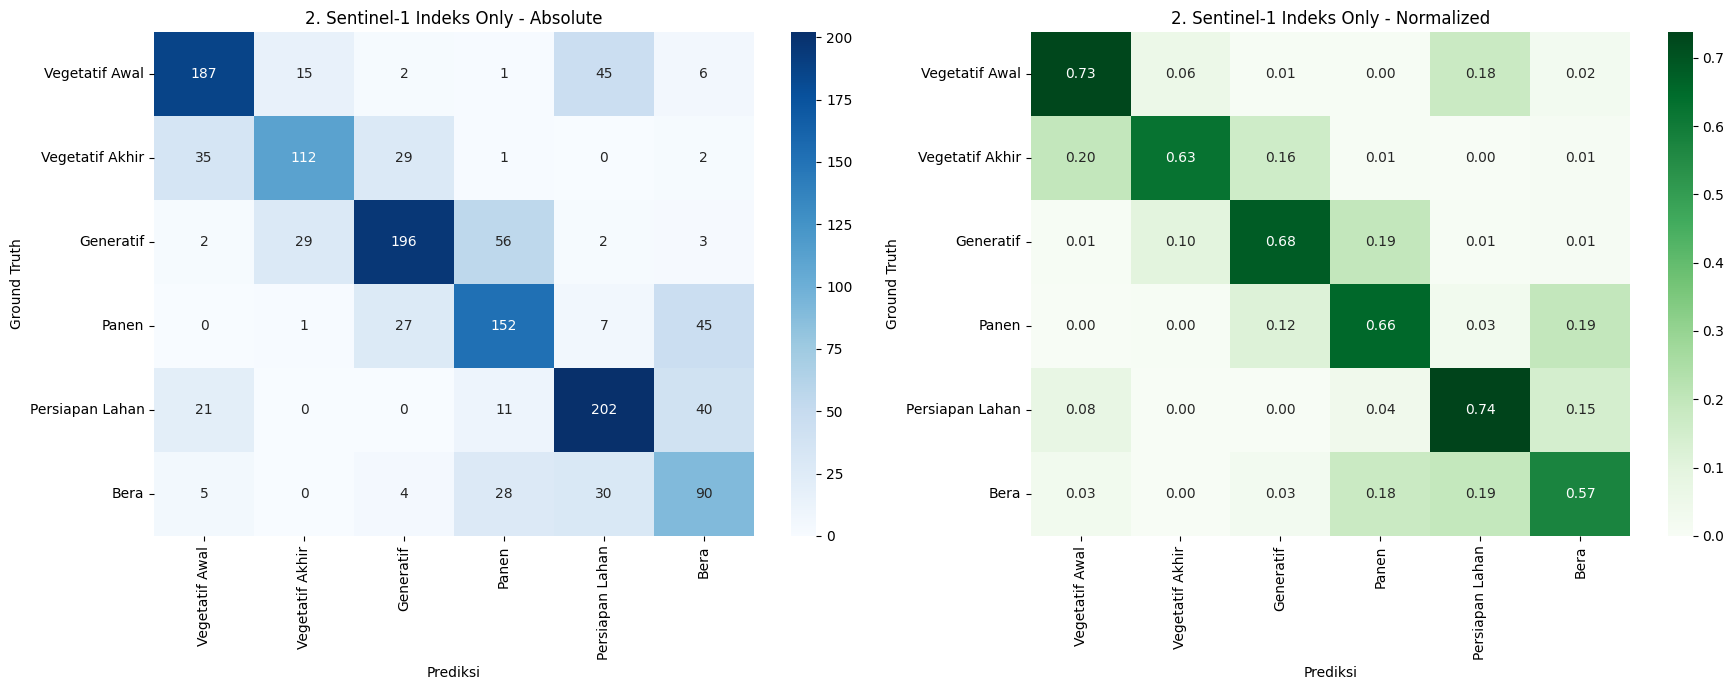


Skenario: 3. Sentinel-1 Complete


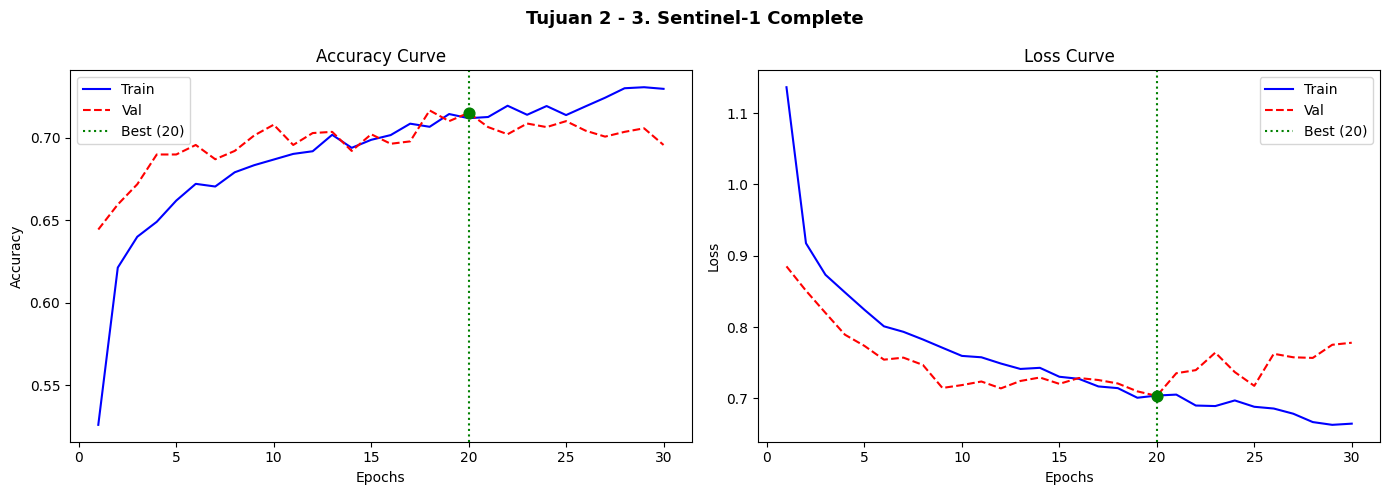

                 precision    recall  f1-score   support

 Vegetatif Awal     0.7918    0.7578    0.7745       256
Vegetatif Akhir     0.7229    0.6704    0.6957       179
      Generatif     0.7593    0.7118    0.7348       288
          Panen     0.6236    0.7069    0.6626       232
Persiapan Lahan     0.7590    0.7701    0.7645       274
           Bera     0.5427    0.5669    0.5545       157

       accuracy                         0.7092      1386
      macro avg     0.6999    0.6973    0.6978      1386
   weighted avg     0.7133    0.7092    0.7104      1386

Test Accuracy : 70.9235%
Cohen's Kappa : 0.6482


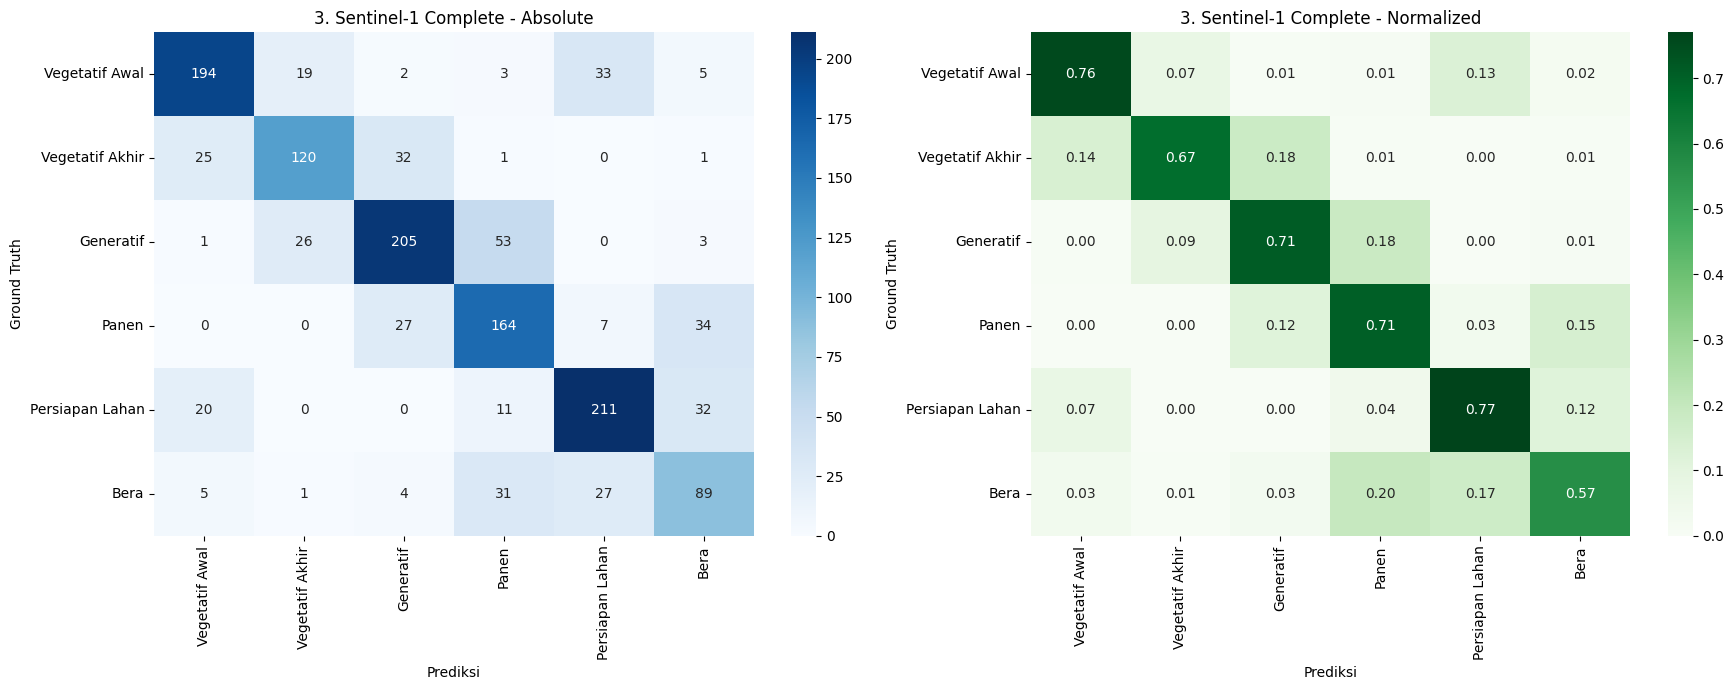


Skenario: 4. Sentinel-2 Bands Only


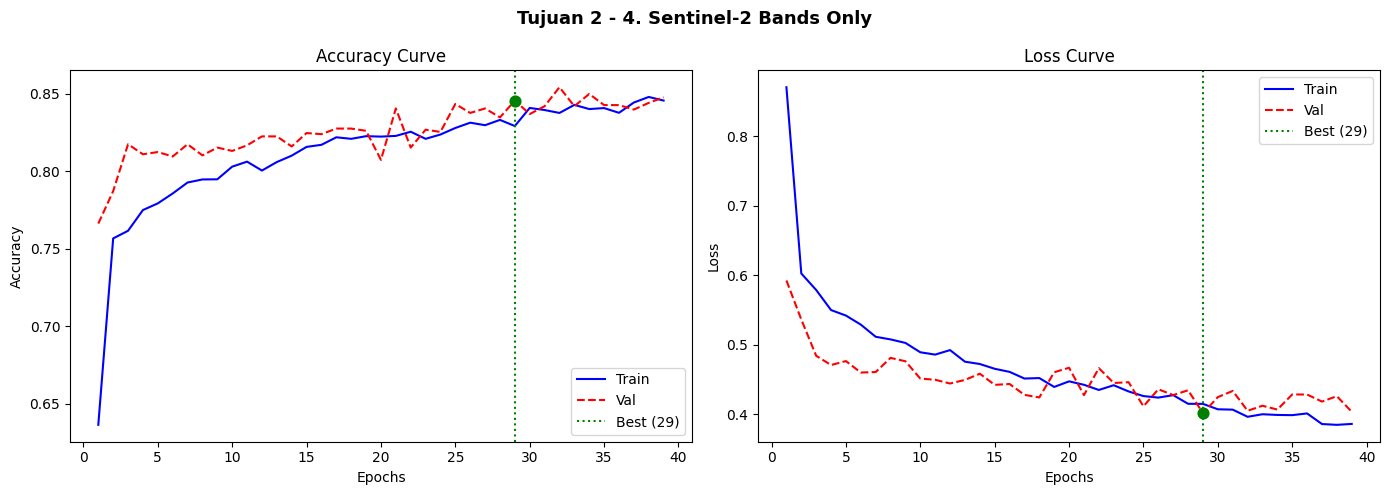

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8699    0.8359    0.8526       256
Vegetatif Akhir     0.8011    0.8101    0.8056       179
      Generatif     0.8797    0.8889    0.8843       288
          Panen     0.8435    0.8362    0.8398       232
Persiapan Lahan     0.8191    0.8759    0.8466       274
           Bera     0.8138    0.7516    0.7815       157

       accuracy                         0.8420      1386
      macro avg     0.8379    0.8331    0.8350      1386
   weighted avg     0.8422    0.8420    0.8417      1386

Test Accuracy : 84.1991%
Cohen's Kappa : 0.8085


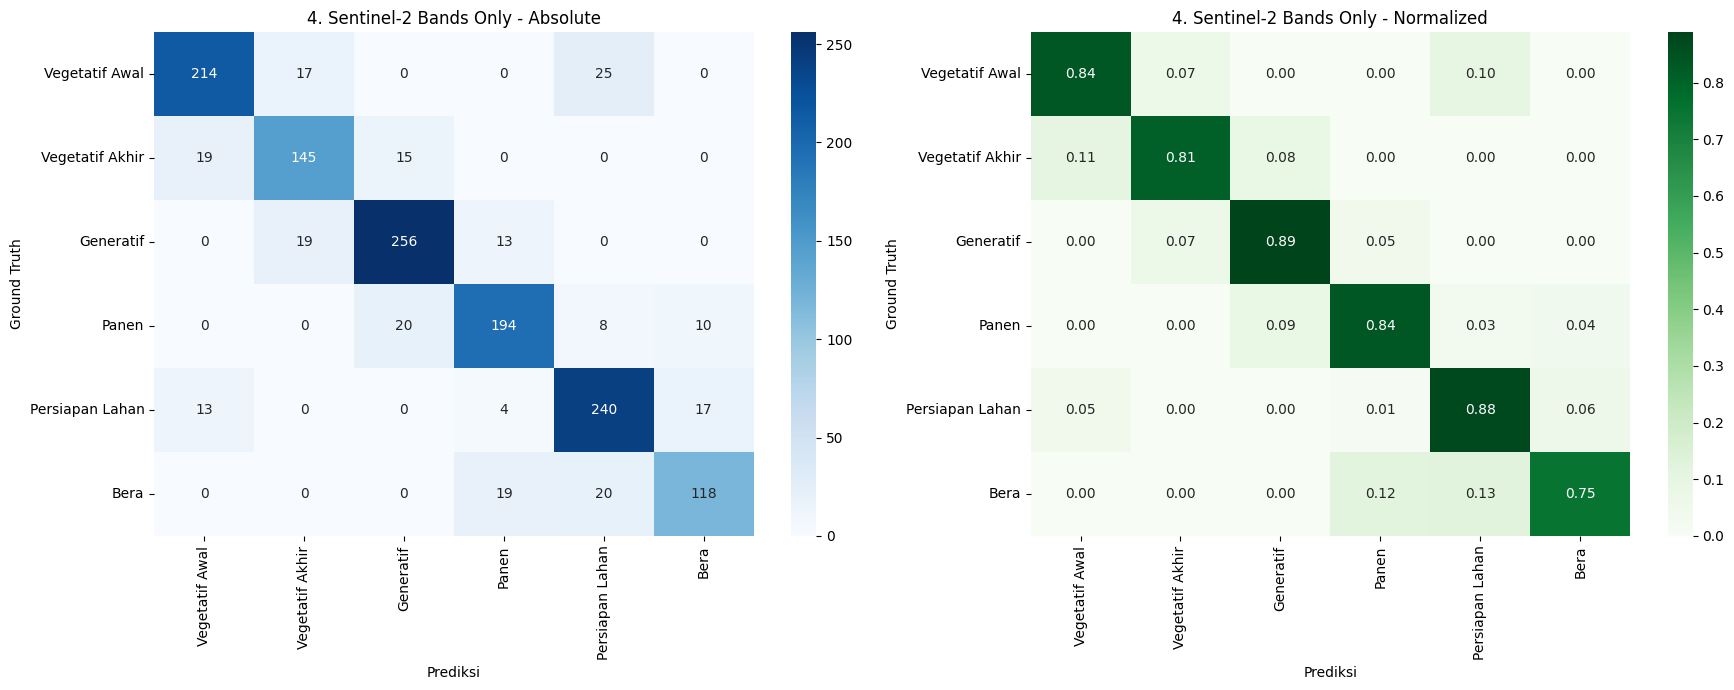


Skenario: 5. Sentinel-2 Indeks Only


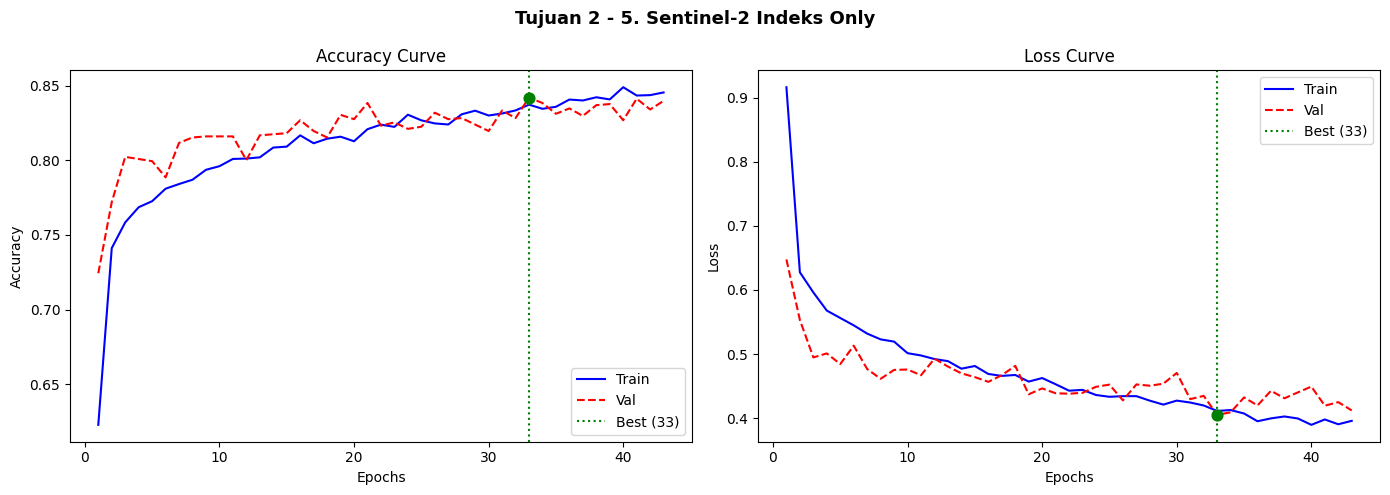

                 precision    recall  f1-score   support

 Vegetatif Awal     0.9018    0.7891    0.8417       256
Vegetatif Akhir     0.8042    0.8492    0.8261       179
      Generatif     0.8750    0.8993    0.8870       288
          Panen     0.8340    0.8664    0.8499       232
Persiapan Lahan     0.8121    0.8358    0.8237       274
           Bera     0.7727    0.7580    0.7653       157

       accuracy                         0.8384      1386
      macro avg     0.8333    0.8329    0.8323      1386
   weighted avg     0.8399    0.8384    0.8383      1386

Test Accuracy : 83.8384%
Cohen's Kappa : 0.8044


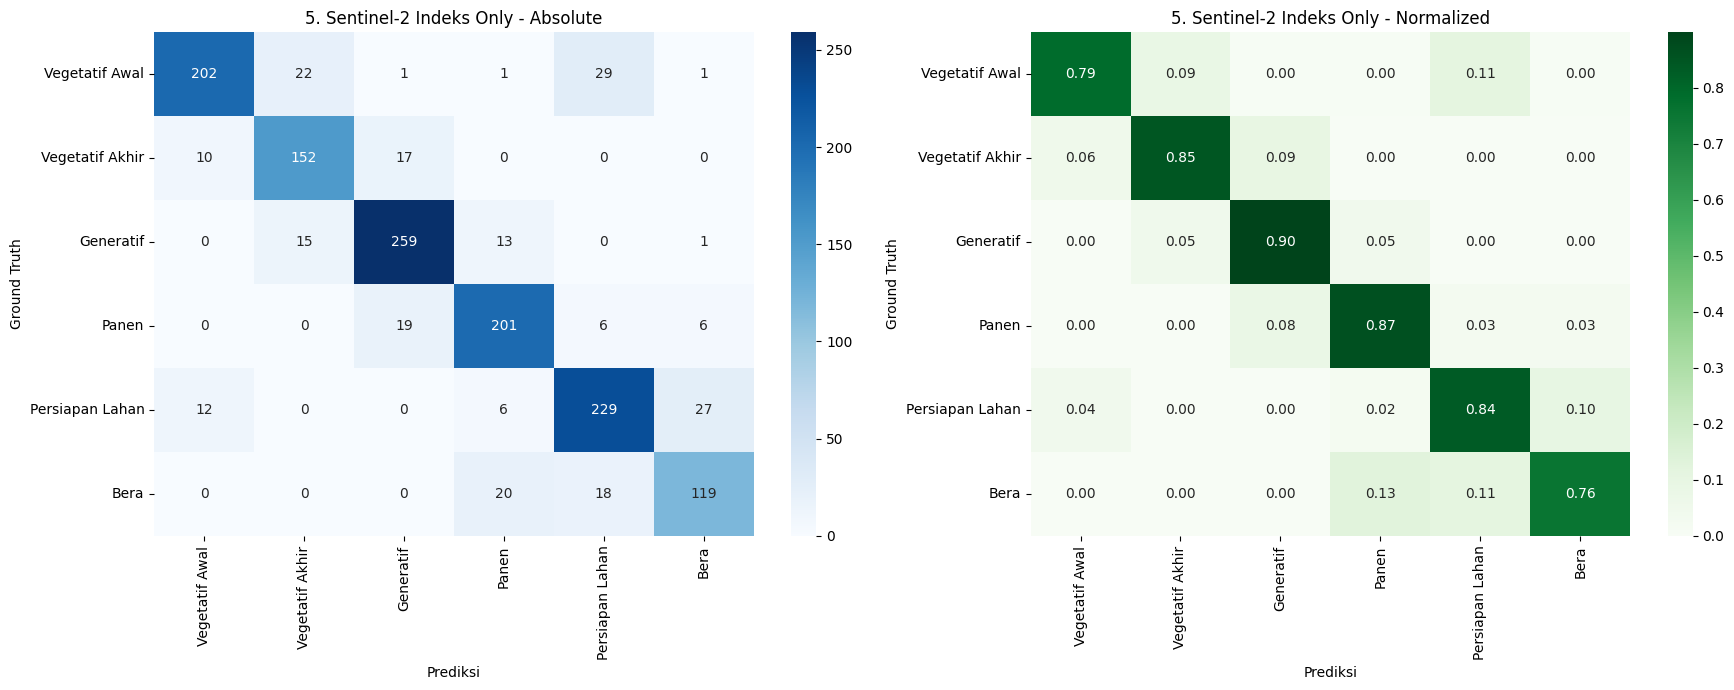


Skenario: 6. Sentinel-2 Complete


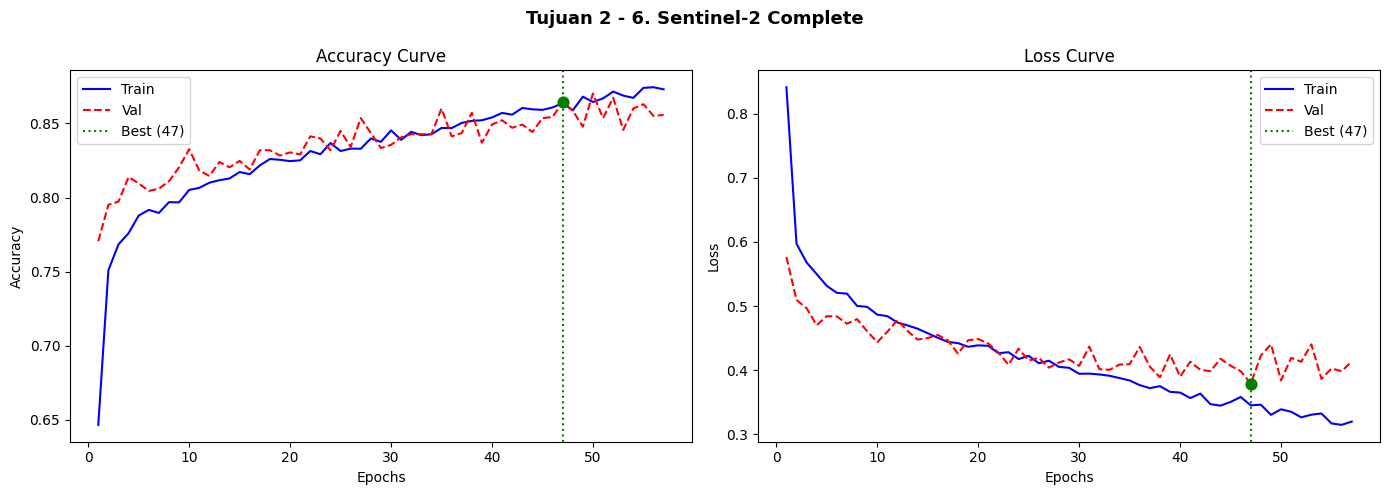

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8926    0.8438    0.8675       256
Vegetatif Akhir     0.7989    0.8436    0.8207       179
      Generatif     0.8772    0.8681    0.8726       288
          Panen     0.8375    0.8664    0.8517       232
Persiapan Lahan     0.8571    0.8540    0.8556       274
           Bera     0.7834    0.7834    0.7834       157

       accuracy                         0.8478      1386
      macro avg     0.8411    0.8432    0.8419      1386
   weighted avg     0.8487    0.8478    0.8480      1386

Test Accuracy : 84.7763%
Cohen's Kappa : 0.8158


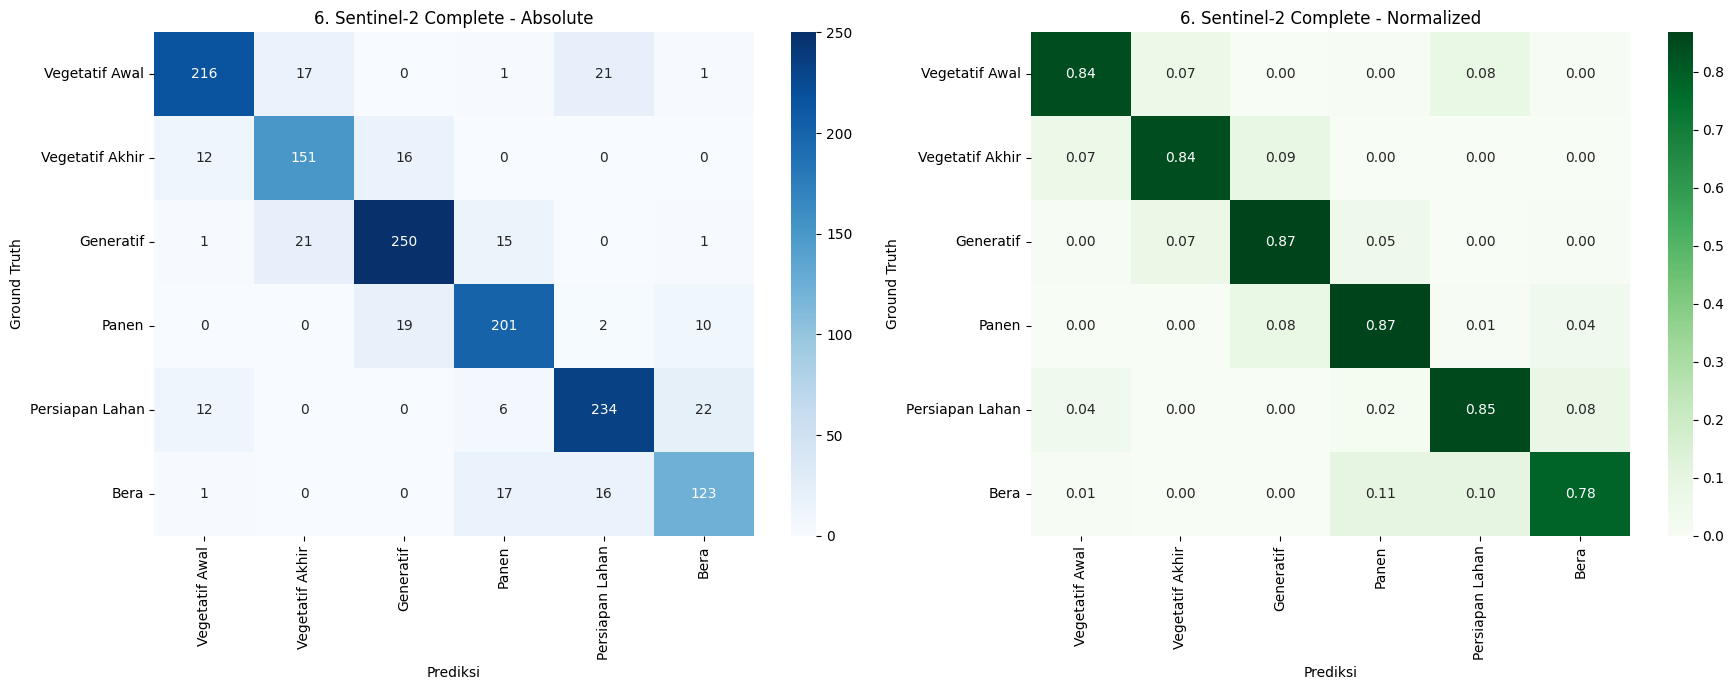


Skenario: 7. Sentinel-1 + Sentinel-2 Band


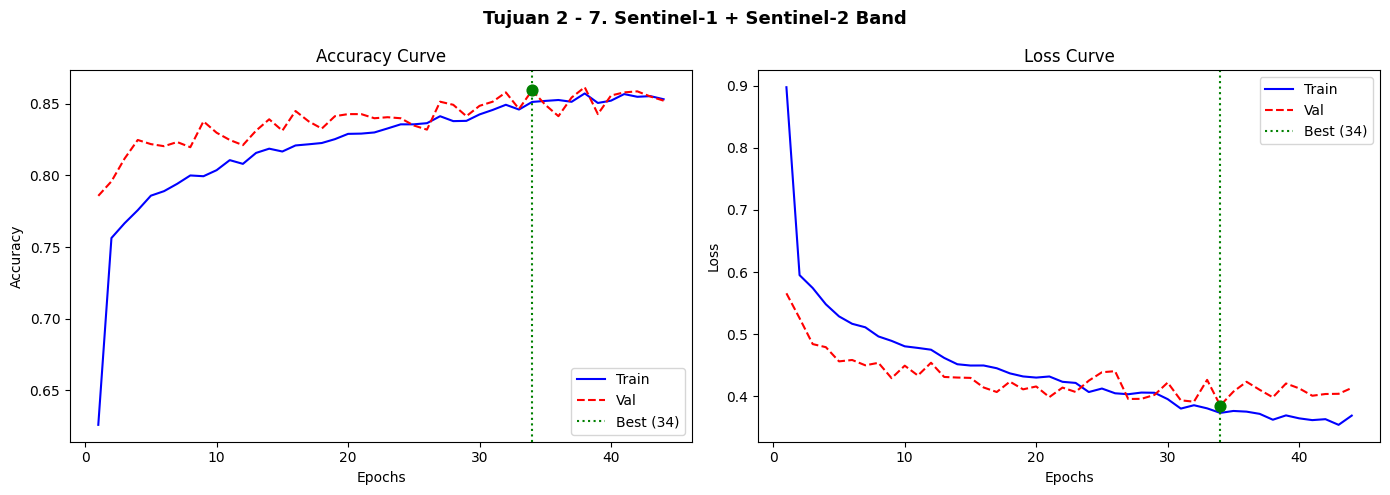

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8880    0.8359    0.8612       256
Vegetatif Akhir     0.7846    0.8547    0.8182       179
      Generatif     0.8974    0.8507    0.8734       288
          Panen     0.8270    0.8448    0.8358       232
Persiapan Lahan     0.8333    0.8394    0.8364       274
           Bera     0.7378    0.7707    0.7539       157

       accuracy                         0.8362      1386
      macro avg     0.8280    0.8327    0.8298      1386
   weighted avg     0.8386    0.8362    0.8369      1386

Test Accuracy : 83.6219%
Cohen's Kappa : 0.8021


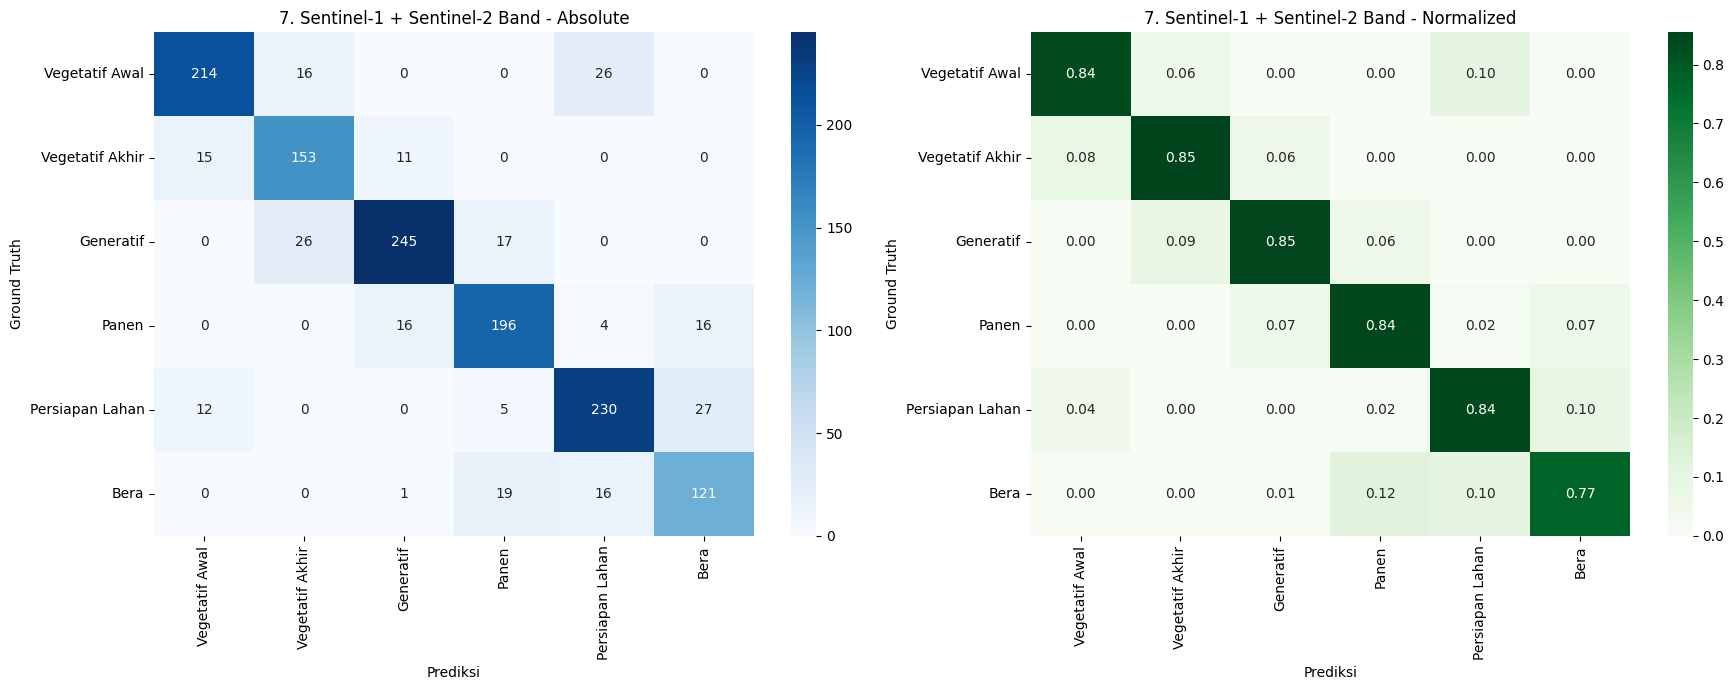


Skenario: 8. Sentinel-1 + Sentinel-2 Indeks


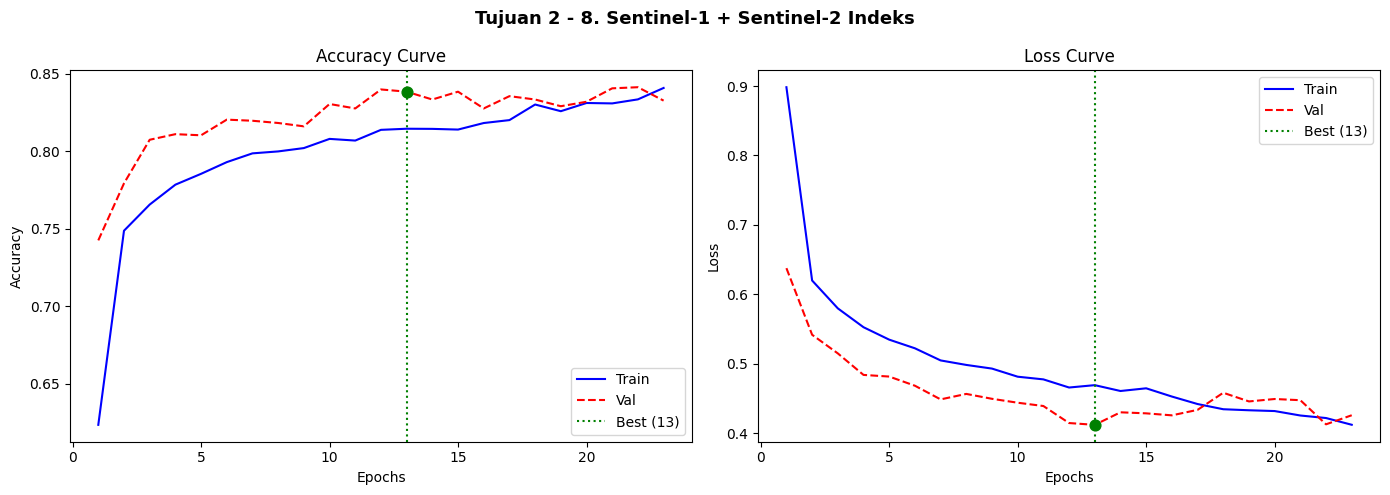

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8809    0.8086    0.8432       256
Vegetatif Akhir     0.7869    0.8045    0.7956       179
      Generatif     0.8681    0.8681    0.8681       288
          Panen     0.7968    0.8621    0.8282       232
Persiapan Lahan     0.8068    0.8686    0.8366       274
           Bera     0.7985    0.6815    0.7354       157

       accuracy                         0.8268      1386
      macro avg     0.8230    0.8156    0.8178      1386
   weighted avg     0.8280    0.8268    0.8262      1386

Test Accuracy : 82.6840%
Cohen's Kappa : 0.7901


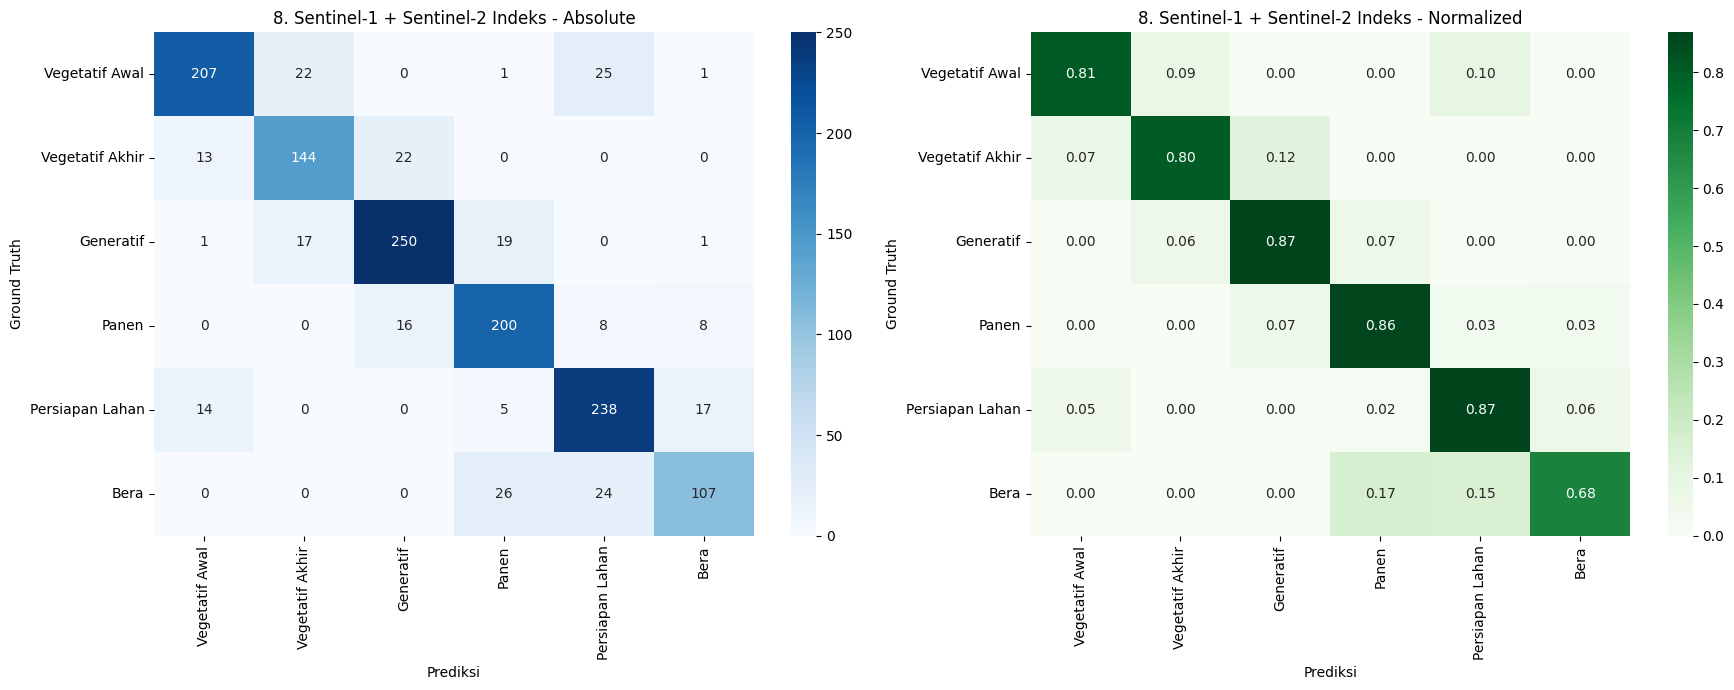


Skenario: 9. Sentinel-1 + Sentinel-2 Complete


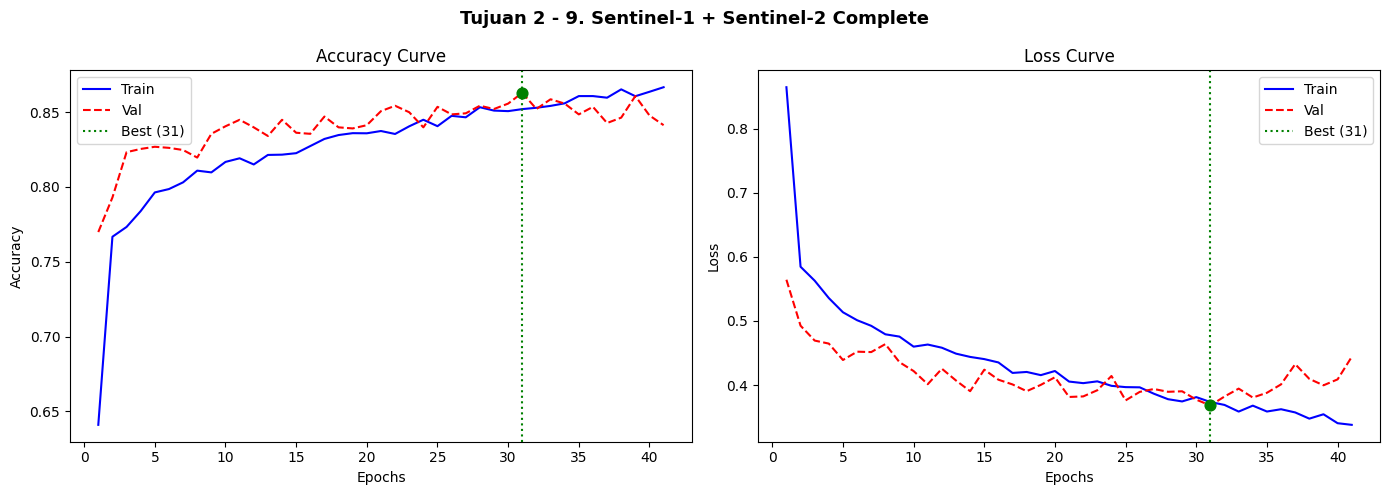

                 precision    recall  f1-score   support

 Vegetatif Awal     0.8750    0.8203    0.8468       256
Vegetatif Akhir     0.7937    0.8380    0.8152       179
      Generatif     0.9055    0.8646    0.8845       288
          Panen     0.8559    0.8707    0.8632       232
Persiapan Lahan     0.8291    0.8321    0.8306       274
           Bera     0.7485    0.8153    0.7805       157

       accuracy                         0.8420      1386
      macro avg     0.8346    0.8402    0.8368      1386
   weighted avg     0.8442    0.8420    0.8426      1386

Test Accuracy : 84.1991%
Cohen's Kappa : 0.8090


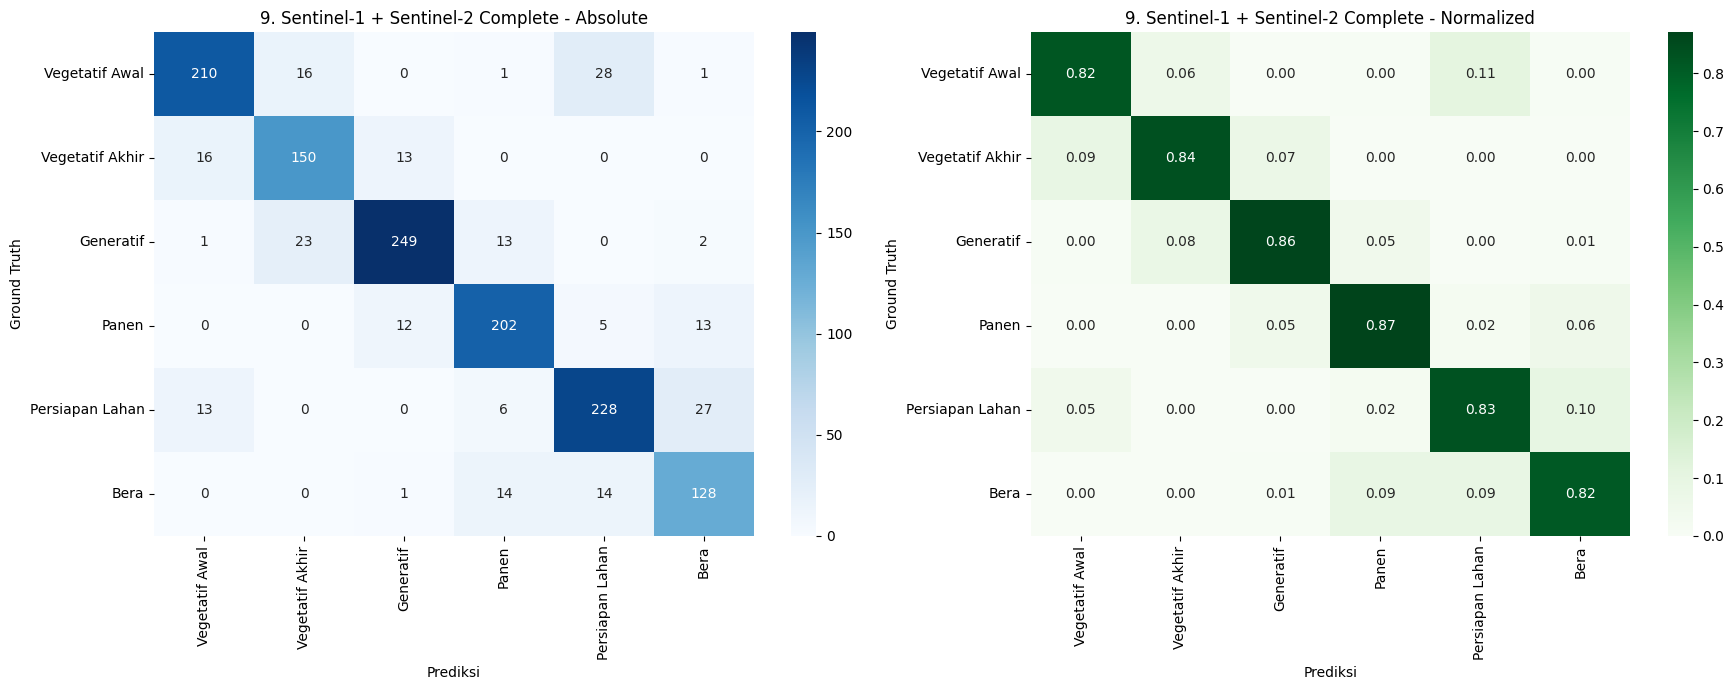

In [13]:
# ── EVALUASI PER SKENARIO ───────────────────────────────────────────
for name, feat_idx in T2_SCENARIOS.items():
    safe_name    = name.replace(" ", "_").replace(".", "").replace("-", "")
    path_model   = os.path.join(T2_DIR_MODEL,   f"BestModel_{safe_name}.keras")
    path_history = os.path.join(T2_DIR_HISTORY, f"History_{safe_name}.pkl")

    if not (os.path.exists(path_model) and os.path.exists(path_history)):
        print(f"Skip {name}: file tidak ditemukan.")
        continue

    print(f"\n{'='*60}\nSkenario: {name}\n{'='*60}")

    with open(path_history, 'rb') as f:
        h = pickle.load(f)

    lc_path = os.path.join(T2_BASE_DIR, f"LC_{safe_name}.png")

    # Learning Curve
    plot_learning_curve(h, f"Tujuan 2 - {name}", save_path=lc_path)

    X_te      = X_test_sc[:, :, feat_idx]
    model_s   = load_model(path_model, custom_objects={'subset_output': subset_output})
    cm_path   = os.path.join(T2_BASE_DIR, f"CM_{safe_name}.png")

    # Evaluasi
    evaluate_model(model_s, X_te, y_test, NAMA_KELAS, title=name, save_dir=T2_BASE_DIR)
    K.clear_session()

In [ ]:
# ── VERIFIKASI KONSISTENSI TUJUAN 1a vs TUJUAN 2 (Skenario 12 Fitur) ────────
print("Verifikasi konsistensi hasil skenario 12 fitur (T2) vs Tujuan 1a...")

# Ambil hasil skenario '9. Sentinel-1 + Sentinel-2 Complete' dari T2
skenario_12f = "9. Sentinel-1 + Sentinel-2 Complete"
if 'df_t2' in dir() and not df_t2.empty:
    row_12f = df_t2[df_t2['Skenario'] == skenario_12f]
    if not row_12f.empty:
        print(f"\n[Tujuan 2 - 12 Fitur]")
        print(f"  Val Acc  : {row_12f['Val Accuracy'].values[0]:.4%}")
        print(f"  Test Acc : {row_12f['Test Accuracy'].values[0]:.4%}")

# Ambil hasil Tujuan 1a dari Excel
if os.path.exists(T1A_PATH_EXCEL):
    df_1a = pd.read_excel(T1A_PATH_EXCEL)
    if 'BEST_TRIAL_MODEL' in dir():
        trial_id = int(BEST_TRIAL_MODEL.split('_')[1])
        row_1a = df_1a[df_1a['Trial ID'] == trial_id]
        if not row_1a.empty:
            print(f"\n[Tujuan 1a - Best Trial {trial_id}]")
            print(f"  Val Acc  : {row_1a['Val Acc'].values[0]:.4%}")

Verifikasi konsistensi hasil skenario 12 fitur (T2) vs Tujuan 1a...

[Tujuan 1a - Best Trial 15]
  Val Acc  : 86.2915%


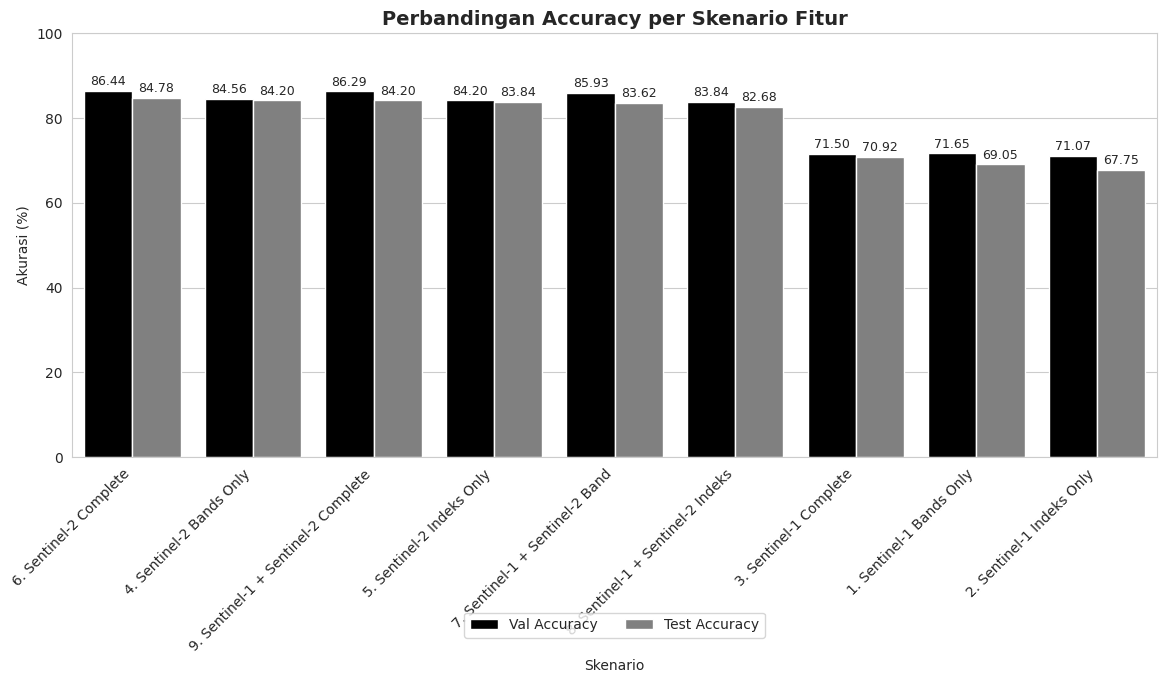

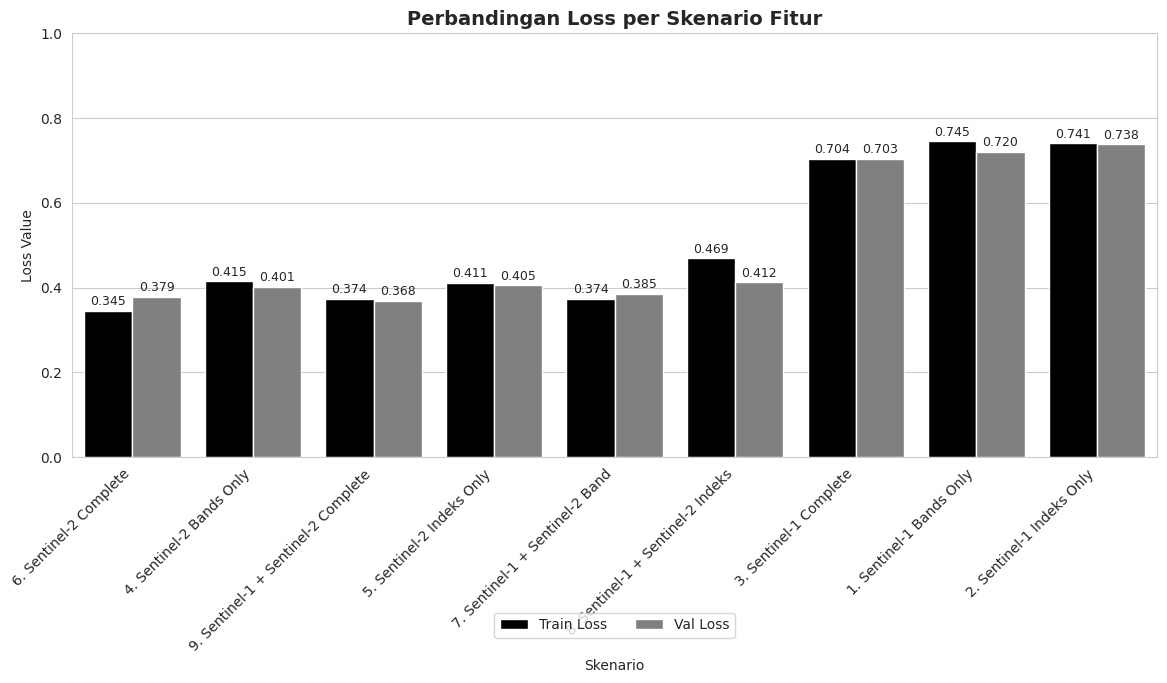

In [ ]:
# ── GRAFIK PERBANDINGAN SKENARIO ─────────────────────────────────────────────
if 'df_t2' not in dir() or df_t2.empty:
    df_t2 = pd.read_excel(T2_PATH_EXCEL)

df_sorted = df_t2.sort_values('Test Accuracy', ascending=False)
sns.set_style("whitegrid")

# Grafik Accuracy
df_acc = df_sorted.melt(id_vars=['Skenario'],
                        value_vars=['Val Accuracy', 'Test Accuracy'],
                        var_name='Tipe', value_name='Accuracy')
df_acc['Accuracy'] *= 100

fig, ax = plt.subplots(figsize=(14, 8))
sns.barplot(x='Skenario', y='Accuracy', hue='Tipe',
            data=df_acc, palette=['black', 'gray'], ax=ax)
ax.set_title('Perbandingan Accuracy per Skenario Fitur', fontsize=14, fontweight='bold')
ax.set_xlabel('Skenario'); ax.set_ylabel('Akurasi (%)')
plt.xticks(rotation=45, ha='right'); plt.ylim(0, 100)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', padding=2, fontsize=9)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=2)
plt.subplots_adjust(bottom=0.35)
plt.savefig(os.path.join(T2_BASE_DIR, 'Grafik_Accuracy_Skenario.png'), dpi=150, bbox_inches='tight')
plt.show()

# Grafik Loss
df_loss = df_sorted.melt(id_vars=['Skenario'],
                         value_vars=['Train Loss', 'Val Loss'],
                         var_name='Tipe', value_name='Loss')

fig, ax = plt.subplots(figsize=(14, 8))
sns.barplot(x='Skenario', y='Loss', hue='Tipe',
            data=df_loss, palette=['black', 'gray'], ax=ax)
ax.set_title('Perbandingan Loss per Skenario Fitur', fontsize=14, fontweight='bold')
ax.set_xlabel('Skenario'); ax.set_ylabel('Loss Value')
plt.xticks(rotation=45, ha='right'); plt.ylim(0, 1)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', padding=2, fontsize=9)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=2)
plt.subplots_adjust(bottom=0.35)
plt.savefig(os.path.join(T2_BASE_DIR, 'Grafik_Loss_Skenario.png'), dpi=150, bbox_inches='tight')
plt.show()


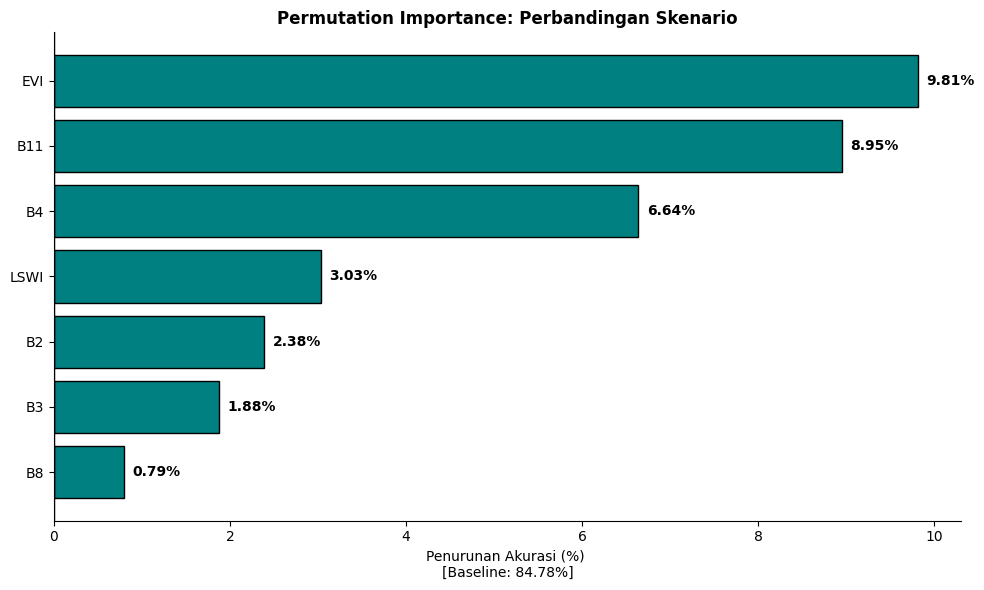

In [ ]:
# ── FEATURE IMPORTANCE PERMUTATION (PER SKENARIO) ────────────────────────────
def calculate_permutation_importance_skenario(model, X_test, y_test, fitur_skenario):
    y_true_flat  = y_test.argmax(axis=2).flatten()
    baseline_acc = accuracy_score(
        y_true_flat, model.predict(X_test, verbose=0).argmax(axis=2).flatten()
    )
    results = {}
    for i, feat in enumerate(fitur_skenario):
        X_perm = X_test.copy()
        np.random.seed(42)
        # np.random.shuffle(X_perm[:, :, i])
        acak_idx = np.random.permutation(len(X_perm))
        X_perm[:, :, i] = X_perm[acak_idx, :, i]
        perm_acc = accuracy_score(
            y_true_flat, model.predict(X_perm, verbose=0).argmax(axis=2).flatten()
        )
        results[feat] = baseline_acc - perm_acc
    return results, baseline_acc

fitur_asli     = CONFIG['features']
fitur_skenario = ['B2', 'B3', 'B4', 'B8', 'B11', 'EVI', 'LSWI'] # ini ga boleh ketuker
idx_fitur      = [fitur_asli.index(f) for f in fitur_skenario]
X_test_skenario = X_test_sc[:, :, idx_fitur]

daftar_model = ['BestModel_6_Sentinel2_Complete.keras']

for nama_model in daftar_model:
    model_best = load_model(
        os.path.join(T2_DIR_MODEL, nama_model),
        custom_objects={'subset_output': subset_output}
    )
    feat_imp, base_acc = calculate_permutation_importance_skenario(
        model_best, X_test_skenario, y_test, fitur_skenario
    )

    sorted_imp = dict(sorted(feat_imp.items(), key=lambda x: x[1], reverse=True))
    plt.figure(figsize=(10, 6))
    bars = plt.barh(list(sorted_imp.keys()),
                    [v*100 for v in sorted_imp.values()],
                    color='teal', edgecolor='black')
    plt.axvline(0, color='black', lw=1)
    plt.xlabel(f'Penurunan Akurasi (%) \n[Baseline: {base_acc*100:.2f}%]')
    plt.title(f'Permutation Importance: {T2_NAMA}', fontweight='bold')
    plt.gca().invert_yaxis()
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.grid(False)
    for bar in bars:
        w = bar.get_width()
        plt.text(w + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{w:.2f}%', va='center', fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(T2_BASE_DIR, f'FI_{nama_model}.png'), dpi=300)
    plt.show()